# ML3 - Customer Segmentation (Olist)
K-Means customer segmentation on the Olist Brazilian e-commerce data.

| Part | Steps | Content |
|---|---|---|
| 1 | 0 to 3 | Imports and settings, load and merge tables, clean the merged data, aggregate to one row per customer |
| 2 | 4 | Feature transformation, feature sets, standardization, correlation check |
| 3 | 5 | K-Means on original features vs K-Means on PCA components, with metrics and plots |
| 4 | 6 | DBSCAN on the same features, its metrics and maps, and the comparison with K-Means |
**Input used from now on:** `ml3_features_A_delivered.csv` (set in the settings cell with `INPUT_FILE`), so Steps 1 to 4.1 are skipped and the notebook starts at Step 4.2.

**Entry points.** You do not need to upload every table. The notebook looks at the files in `DATA_DIR`, recognizes which step each file belongs to (from its columns) and starts from the furthest step it can, skipping everything before it:

| You provide | Recognized by | Notebook starts at |
|---|---|---|
| the 5 raw tables (`orders_master.csv`, ...) | the file names in `FILES` | Step 1 (everything runs) |
| `ml3_orders_merged_A_delivered.csv` | order-level columns (`order_id`, `total_paid`, `category`, ...) | Step 3 |
| `ml3_customers_A_delivered.csv` | customer-level columns (`total_spent`, `recency_days`, ...) | Step 4 |
| `ml3_features_A_delivered.csv` | transformed columns (`log_total_spent`, ...) | Step 4.2 (standardize, then K-Means) |

If several are present, the earliest step is used. Force a choice with `START_FROM` or `INPUT_FILE` in the settings cell.


# Part 1 - Setup, merge, cleaning and customer-level dataset (Steps 0 to 3)

| Step | Content |
|---|---|
| 0 | Imports and settings |
| 1 | Load and merge tables (order level) |
| 2 | Clean the merged data |
| 3 | Aggregate to one row per customer |

## Step 0 - Imports and settings
All imports used in the notebook, display options, the fixed random seed, the observation date and the input file names.

In [ ]:
# Imports (all libraries used in the notebook)
import time
import warnings
from itertools import combinations
from pathlib import Path

from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [156]:
# Settings
DATA_DIR = Path(".")                     # folder that contains the CSV files
OBS_DATE = pd.Timestamp("2018-09-01")    # fixed observation date (avoids leakage)
INCLUDE_UNDELIVERED = False              # False = version A (delivered orders only)
DELIVERED_STATUS = 5                     # order_status code that means "delivered"
RANDOM_STATE = 42                        # seed for sampling and PCA

# Where to start. "auto" = detect from the files in DATA_DIR.
# Other values: "raw", "orders_merged", "customers", "features"
START_FROM = "features"                 # input is the features file
# Optional: force one specific CSV as the input (its step is recognized from its columns)
INPUT_FILE = "ml3_features_A_delivered.csv"   # transformed features, one row per customer

# Input file names (raw tables, Step 1)
FILES = {
    "orders":    "orders_master.csv",
    "customers": "olist_customers_clean.csv",
    "payments":  "order_payments_clean.csv",
    "items":     "olist_order_items_agg_1.csv",
    "products":  "olist_products_clean .csv",
}

# Names of the files this notebook writes (and can read back as an entry point)
version = "B_all" if INCLUDE_UNDELIVERED else "A_delivered"
CUST_FILE = f"ml3_customers_{version}.csv"
FEAT_FILE = f"ml3_features_{version}.csv"


## Step 0b - Detect the starting step
Looks at the CSV files in `DATA_DIR`, recognizes which step of the pipeline each one belongs to from its **columns**, and decides where to start. Earlier steps are skipped automatically (their cells print a "skipped" message), and the input file for the chosen step is loaded here.


In [157]:
# Payment value columns (used in Steps 2 and 3)
value_cols = ["value_boleto", "value_credit_card", "value_debit_card", "value_voucher"]

# Pipeline order: the earlier a stage, the more work the notebook has to do
STAGES = ["raw", "orders_merged", "customers", "features"]

# Columns that identify each kind of file
FEAT_COLS = ["recency_days", "boleto_share", "avg_review_score", "avg_delivery_delay",
             "credit_card_share", "voucher_share", "debit_card_share",
             "log_total_spent", "log_freight_ratio", "log_avg_installments",
             "log_avg_product_volume", "log_recency_days"]
SIGNATURES = {
    "orders_merged": {"order_id", "customer_unique_id", "order_purchase_timestamp", "total_paid",
                      "category", "avg_price", "freight_ratio", "max_installments", "review_score",
                      "delivery_delay_days", "n_items", "product_weight_g", "product_volume_cm3",
                      "customer_state"} | set(value_cols),
    "customers":     {"customer_unique_id", "total_spent", "recency_days", "avg_item_price",
                      "freight_ratio", "avg_installments", "avg_review_score", "avg_delivery_delay",
                      "avg_product_volume_cm3", "boleto_share", "credit_card_share",
                      "debit_card_share", "voucher_share"},
    "features":      set(FEAT_COLS),
}

# 1) Which files are available?
found = {}                                            # stage -> path of the file (None for raw)
if INPUT_FILE is None and all((DATA_DIR / f).exists() for f in FILES.values()):
    found["raw"] = None

candidates = [DATA_DIR / INPUT_FILE] if INPUT_FILE else sorted(DATA_DIR.glob("*.csv"))
candidates = sorted(candidates, key=lambda p: version not in p.name)   # files of this version first
for path in candidates:
    try:
        cols = set(pd.read_csv(path, nrows=0).columns)    # header only, very fast
    except Exception:
        continue
    for stage, needed_cols in SIGNATURES.items():
        if needed_cols <= cols and stage not in found:
            found[stage] = path

# 2) Choose the starting stage
if START_FROM == "auto":
    START_LEVEL = next((s for s in STAGES if s in found), None)
else:
    START_LEVEL = START_FROM
assert START_LEVEL in found, (
    f"Cannot start from '{START_FROM}'. Available inputs: {list(found) or 'none'}. "
    f"Put the raw tables or one of the saved CSVs in {DATA_DIR.resolve()}.")

# 3) Flags used by the guarded cells below
RUN_STEPS_1_2    = START_LEVEL == "raw"                          # load, merge, clean
RUN_STEP_3       = START_LEVEL in ("raw", "orders_merged")       # aggregate to customers
RUN_STEP_4_BUILD = START_LEVEL != "features"                     # build the transformed features

# 4) Load the input of the chosen stage (the raw tables are loaded later in Step 1)
if START_LEVEL == "orders_merged":
    df = pd.read_csv(found["orders_merged"], parse_dates=["order_purchase_timestamp"])
elif START_LEVEL == "customers":
    cust = pd.read_csv(found["customers"])
elif START_LEVEL == "features":
    feat = pd.read_csv(found["features"], index_col=0)

summary = pd.DataFrame({
    "step": ["Steps 1-2 (merge, clean)", "Step 3 (customer table)", "Step 4.1 (transform features)",
             "Steps 4.2-5 (feature sets, standardize, K-Means)"],
    "action": ["run" if f else "skipped" for f in (RUN_STEPS_1_2, RUN_STEP_3, RUN_STEP_4_BUILD, True)],
})
print(f"Starting from: {START_LEVEL}" + (f"  (file: {found[START_LEVEL].name})" if found[START_LEVEL] else "  (raw tables)"))
display(summary)


Starting from: features  (file: ml3_features_A_delivered.csv)


,step,action
0,"Steps 1-2 (merge, clean)",skipped
1,Step 3 (customer table),skipped
2,Step 4.1 (transform features),skipped
3,"Steps 4.2-5 (feature sets, standardize, K-Means)",run


## Step 1 - Load and merge tables (one row = one order)
Loads the five tables, checks that the join keys are unique, keeps the delivered orders and merges the tables with a row count after each merge.

In [158]:
if RUN_STEPS_1_2:
    # Load the five tables
    orders_raw = pd.read_csv(DATA_DIR / FILES["orders"], parse_dates=["order_purchase_timestamp"])
    customers  = pd.read_csv(DATA_DIR / FILES["customers"])
    payments   = pd.read_csv(DATA_DIR / FILES["payments"])
    items      = pd.read_csv(DATA_DIR / FILES["items"])
    products   = pd.read_csv(DATA_DIR / FILES["products"])

    for name, d in [("orders", orders_raw), ("customers", customers), ("payments", payments),
                    ("items", items), ("products", products)]:
        print(f"{name:<10} {d.shape[0]:>8,} rows  {d.shape[1]:>3} columns")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [159]:
if RUN_STEPS_1_2:
    # Check that join keys are unique (so merges cannot duplicate orders)
    assert orders_raw["order_id"].is_unique
    assert customers["customer_id"].is_unique
    assert payments["order_id"].is_unique
    assert items["order_id"].is_unique
    assert products["product_id"].is_unique
    print("All join keys are unique")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [160]:
if RUN_STEPS_1_2:
    # Keep only delivered orders (version A) and start the merge log
    merge_log = []

    def log_step(name, data):
        merge_log.append({"step": name, "rows": len(data)})

    orders = orders_raw.copy()
    if not INCLUDE_UNDELIVERED:
        orders = orders[orders["order_status"] == DELIVERED_STATUS]
    display(log_step("1. orders (base)", orders))
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [161]:
if RUN_STEPS_1_2:
    # Select only the columns we need from each table
    order_cols = ["order_id", "customer_id", "order_status", "order_purchase_timestamp",
                  "review_score", "delivery_delay_days"]
    item_cols = ["order_id", "n_items", "n_products", "total_price", "total_freight",
                 "avg_price", "total_amount", "freight_ratio", "main_product_id"]
    cust_cols = ["customer_id", "customer_unique_id", "customer_state"]
    pay_cols = ["order_id", "total_paid", "max_installments", "value_boleto",
                "value_credit_card", "value_debit_card", "value_voucher"]
    prod_cols = ["product_id", "product_category_name_english", "product_weight_g", "product_volume_cm3"]
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [162]:
if RUN_STEPS_1_2:
    # Merge step by step (inner = drop unmatched, left = keep the order)
    df = orders[order_cols]

    df = df.merge(items[item_cols], on="order_id", how="inner")
    log_step("2. + order_items (inner)", df)

    df = df.merge(customers[cust_cols], on="customer_id", how="inner")
    log_step("3. + customers (inner)", df)

    df = df.merge(payments[pay_cols], on="order_id", how="left")
    log_step("4. + payments (left)", df)

    df = df.merge(products[prod_cols], left_on="main_product_id", right_on="product_id", how="left")
    log_step("5. + products (left)", df)

    # Safety checks: still one row per order
    assert df["order_id"].is_unique
    assert len(df) <= len(orders)

    merge_summary = pd.DataFrame(merge_log)
    merge_summary["rows_lost"] = merge_summary["rows"].shift(1) - merge_summary["rows"]
    display(merge_summary)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [163]:
if RUN_STEPS_1_2:
    # Plot: orders per month (shows the data window and the observation date)
    monthly = df.set_index("order_purchase_timestamp").resample("MS")["order_id"].count()

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(monthly.index, monthly.values, marker="o")
    ax.axvline(OBS_DATE, color="red", linestyle="--", label="observation date")
    ax.set_title("Orders per month (merged dataset)")
    ax.set_ylabel("orders")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


## Step 2 - Clean the merged data (order level)
Removes orders after the observation date, fills missing values, clips extreme values and drops unused columns.

In [164]:
if RUN_STEPS_1_2:
    # Remove orders after the observation date (leakage protection)
    before = len(df)
    df = df[df["order_purchase_timestamp"] <= OBS_DATE].copy()
    print(f"Orders removed after {OBS_DATE.date()}: {before - len(df)}")
    print(f"Last purchase in data: {df['order_purchase_timestamp'].max()}")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [165]:
if RUN_STEPS_1_2:
    # Missing values BEFORE cleaning
    check_cols = ["delivery_delay_days", "review_score", "product_category_name_english",
                  "product_weight_g", "product_volume_cm3", "total_paid", "max_installments"]
    missing_before = df[check_cols].isna().sum()
    delay_before = df["delivery_delay_days"].copy()    # kept for the plot below
    display(missing_before)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [166]:
if RUN_STEPS_1_2:
    # Clean categories and payments
    value_cols = ["value_boleto", "value_credit_card", "value_debit_card", "value_voucher"]

    # Missing category -> "unknown" (the products file already uses "unknown" too)
    df["category"] = df["product_category_name_english"].fillna("unknown")

    # If payment info is missing, use the item total; missing installments -> 1
    df["total_paid"] = df["total_paid"].fillna(df["total_amount"])
    df["max_installments"] = df["max_installments"].fillna(1)
    df[value_cols] = df[value_cols].fillna(0)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [167]:
if RUN_STEPS_1_2:
    # Clean delivery delay: fill missing with median, then clip extreme values (1st-99th percentile)
    df["delivery_delay_days"] = df["delivery_delay_days"].fillna(df["delivery_delay_days"].median())
    lo, hi = df["delivery_delay_days"].quantile([0.01, 0.99])
    df["delivery_delay_days"] = df["delivery_delay_days"].clip(lo, hi)
    print(f"Delivery delay clipped to [{lo:.1f}, {hi:.1f}] days")

    # Clean freight ratio: cap extreme values at the 99th percentile
    cap = df["freight_ratio"].quantile(0.99)
    df["freight_ratio"] = df["freight_ratio"].clip(upper=cap)
    print(f"Freight ratio capped at {cap:.2f}")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [168]:
if RUN_STEPS_1_2:
    # Drop columns we no longer need
    df = df.drop(columns=["total_amount", "product_category_name_english", "product_id", "order_status"])

    # Missing values AFTER cleaning (review score and product size are handled at customer level)
    missing_after = df[["delivery_delay_days", "review_score", "category",
                        "product_weight_g", "product_volume_cm3", "total_paid", "max_installments"]].isna().sum()
    display(pd.DataFrame({"before": missing_before.rename(index={"product_category_name_english": "category"}),
                  "after": missing_after}))
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [169]:
if RUN_STEPS_1_2:
    # Plot: delivery delay before and after cleaning
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
    axes[0].hist(delay_before.dropna(), bins=60, color="steelblue")
    axes[0].set_title("Delivery delay - before (days)")
    axes[1].hist(df["delivery_delay_days"], bins=60, color="seagreen")
    axes[1].set_title("Delivery delay - after (days)")
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [170]:
if RUN_STEPS_1_2:
    # Plot: how many orders per category (top 15)
    top_cat = df["category"].value_counts().head(15)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.barplot(x=top_cat.values, y=top_cat.index, color="steelblue", ax=ax)
    ax.set_title("Top 15 categories by number of orders")
    ax.set_xlabel("orders")
    plt.tight_layout()
    plt.show()
    print(f"Total categories: {df['category'].nunique()}")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


## Step 3 - Aggregate to one row per customer (`customer_unique_id`)
Builds the customer table: spending, price, freight, installments, review score, delivery delay, product size, recency, payment shares, state and main category.

In [171]:
if RUN_STEP_3:
    # Total money from all payment types (used later to compute payment shares)
    df["value_total"] = df[value_cols].sum(axis=1)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [172]:
if RUN_STEP_3:
    # Main aggregation: one row per real customer
    cust = (
        df.groupby("customer_unique_id")
          .agg(
              n_orders=("order_id", "nunique"),            # profiling only
              last_purchase=("order_purchase_timestamp", "max"),
              total_spent=("total_paid", "sum"),
              avg_order_value=("total_paid", "mean"),
              avg_item_price=("avg_price", "mean"),
              freight_ratio=("freight_ratio", "mean"),
              avg_installments=("max_installments", "mean"),
              avg_review_score=("review_score", "mean"),
              avg_delivery_delay=("delivery_delay_days", "mean"),
              n_items=("n_items", "sum"),                  # profiling only
              n_categories=("category", "nunique"),        # profiling only
              avg_product_weight_g=("product_weight_g", "mean"),
              avg_product_volume_cm3=("product_volume_cm3", "mean"),
              sum_boleto=("value_boleto", "sum"),
              sum_credit_card=("value_credit_card", "sum"),
              sum_debit_card=("value_debit_card", "sum"),
              sum_voucher=("value_voucher", "sum"),
              sum_value_total=("value_total", "sum"),
          )
          .reset_index()
    )
    print(f"Customers: {len(cust):,}")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [173]:
if RUN_STEP_3:
    # Recency and payment shares
    cust["recency_days"] = (OBS_DATE - cust["last_purchase"]).dt.days

    for pay_type in ["boleto", "credit_card", "debit_card", "voucher"]:
        share = np.where(cust["sum_value_total"] > 0, cust[f"sum_{pay_type}"] / cust["sum_value_total"], 0)
        cust[f"{pay_type}_share"] = np.clip(share, 0, 1)

    cust = cust.drop(columns=[c for c in cust.columns if c.startswith("sum_")] + ["last_purchase"])
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [174]:
if RUN_STEP_3:
    # Add profiling columns: state and main category
    # State = state of the most recent order (a few customers appear in 2 states)
    state = (df.sort_values("order_purchase_timestamp")
               .groupby("customer_unique_id")["customer_state"].last())

    # Main category = most frequent category of the customer (ties: first found)
    cat_counts = (df.groupby(["customer_unique_id", "category"]).size().reset_index(name="n")
                    .sort_values(["customer_unique_id", "n"], ascending=[True, False]))
    main_cat = cat_counts.drop_duplicates("customer_unique_id").set_index("customer_unique_id")["category"]

    cust = cust.merge(state.rename("customer_state"), on="customer_unique_id")
    cust = cust.merge(main_cat.rename("main_category"), on="customer_unique_id")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [175]:
if RUN_STEP_3:
    # Fill remaining missing values with the median
    fill_cols = ["avg_review_score", "avg_product_weight_g", "avg_product_volume_cm3"]
    print("Missing before fill:")
    print(cust[fill_cols].isna().sum())

    for c in fill_cols:
        cust[c] = cust[c].fillna(cust[c].median())
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [176]:
if RUN_STEP_3:
    # Final checks on the customer dataset
    assert cust["customer_unique_id"].is_unique
    assert cust.drop(columns=["main_category", "customer_state"]).isna().sum().sum() == 0

    print(f"Shape: {cust.shape}")
    print(f"Repeat customers (n_orders > 1): {(cust['n_orders'] > 1).mean():.2%}")
    display(cust.head())
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [177]:
if RUN_STEP_3:
    # Summary statistics
    display(cust.describe().T)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


### Quick visual checks of the customer dataset

In [178]:
if RUN_STEP_3:
    # Plot: number of orders per customer (why frequency is not used for clustering)
    order_dist = cust["n_orders"].clip(upper=4).value_counts().sort_index()
    labels = ["1", "2", "3", "4+"]

    fig, ax = plt.subplots(figsize=(6, 3.5))
    bars = ax.bar(labels, order_dist.values, color="steelblue")
    for b, v in zip(bars, order_dist.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v / len(cust):.1%}", ha="center", va="bottom")
    ax.set_title("Orders per customer")
    ax.set_xlabel("number of orders")
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [179]:
if RUN_STEP_3:
    # Plot: raw distributions of the candidate features (shows skew)
    plot_cols = ["recency_days", "total_spent", "avg_item_price", "freight_ratio",
                 "avg_installments", "avg_review_score", "avg_delivery_delay",
                 "credit_card_share", "boleto_share", "voucher_share", "debit_card_share",
                 "avg_product_weight_g", "avg_product_volume_cm3"]

    fig, axes = plt.subplots(5, 3, figsize=(14, 14))
    for ax, c in zip(axes.ravel(), plot_cols):
        ax.hist(cust[c], bins=50, color="steelblue")
        ax.set_title(f"{c} (skew = {cust[c].skew():.1f})", fontsize=10)
    for ax in axes.ravel()[len(plot_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [180]:
if RUN_STEP_3:
    # Plot: top categories and states (customers vs revenue share)
    def share_plot(col, title, ax):
        t = cust.groupby(col).agg(customers=("customer_unique_id", "count"), revenue=("total_spent", "sum"))
        t = (t / t.sum()).sort_values("customers", ascending=False).head(10)
        t.plot.barh(ax=ax)
        ax.invert_yaxis()
        ax.set_title(title)
        ax.set_xlabel("share of total")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    share_plot("main_category", "Top 10 main categories", axes[0])
    share_plot("customer_state", "Top 10 states", axes[1])
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [181]:
if RUN_STEP_3:
    # Plot: spending vs item price (are they different signals?)
    sample = cust.sample(min(10000, len(cust)), random_state=42)

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(np.log1p(sample["avg_item_price"]), np.log1p(sample["total_spent"]), s=5, alpha=0.3)
    ax.set_xlabel("log(1 + avg_item_price)")
    ax.set_ylabel("log(1 + total_spent)")
    ax.set_title("Spending vs item price (10,000 sample)")
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


### Save the customer dataset
Writes the customer table to CSV.

In [182]:
if RUN_STEP_3:
    # Save the customer dataset to CSV
    version = "B_all" if INCLUDE_UNDELIVERED else "A_delivered"
    out_name = f"ml3_customers_{version}.csv"
    cust.to_csv(DATA_DIR / out_name, index=False)
    print(f"Saved: {out_name}  {cust.shape}")
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


In [183]:
if RUN_STEP_3:
    # Download the customer and order-level datasets (Google Colab only, skipped elsewhere)
    try:
        from google.colab import files
    except ImportError:
        print("Not running in Colab: download skipped")
    else:
        # Customer-level dataset (one row per customer, used for clustering)
        files.download(out_name)

        # Order-level merged dataset (one row per order, after the merge and cleaning)
        orders_out = f"ml3_orders_merged_{version}.csv"
        df.to_csv(orders_out, index=False)
        files.download(orders_out)
else:
    print('Skipped: starting from a later step')

Skipped: starting from a later step


# Part 2 - Transformations, feature sets and correlation check (Step 4)

Starts from the customer table (one row per customer) and prepares the matrices used by K-Means.

| Step | Content |
|---|---|
| 4.0 | Loading the customer table |
| 4.1 | Transform features (log for skewed ones, none for the others) |
| 4.2 | Define the 4 feature sets to compare (A, B, C, D) |
| 4.3 | Standardize each feature set |
| 4.4 | Correlation check on each set |
| 4.5 | Final checks and saving |

## 4.0 - Loading the customer table
Uses the `cust` table from Part 1 when it exists in memory, otherwise reads the saved customer CSV. The customer id becomes the row label so that every derived table stays aligned row by row.
**Starting from the features file?** Then there is no customer table with readable values, so this step is skipped and `feat` is read from the file directly (done in Step 0b).


In [184]:
# Prepare the customer table `base` (readable values). `cust` comes from Part 1 or from the input file.
if START_LEVEL == "features":
    base = None
    print(f"Starting from the features file: customer table not available, `feat` already loaded {feat.shape}")
else:
    base = cust.copy()
    print(f"Using the customer table (start level: {START_LEVEL})")

    # Use the customer id as the row label, so every table we build stays aligned row by row.
    # The 'if' makes this cell safe to run twice.
    if "customer_unique_id" in base.columns:
        base = base.set_index("customer_unique_id")

    print(f"Customers: {len(base):,} | columns: {base.shape[1]}")
    display(base.head(3))


Starting from the features file: customer table not available, `feat` already loaded (92661, 12)


## 4.1 - Transform features
K-Means measures distances, so a feature with a long tail (a few huge values) would dominate the result. We reduce skew with `log1p(x) = ln(1 + x)`, but only where the histograms showed a real skew problem. Features that are already balanced, binary or whole-number scores are left as they are.

| Feature | Transform | Reason (from the histograms) |
|---|---|---|
| `recency_days` | none | skew 0.4, already balanced |
| `total_spent` | log1p | skew 9.2 |
| `freight_ratio` | log1p | skew 2.1 |
| `avg_installments` | log1p | skew 1.6, most customers have 1 |
| `avg_product_volume_cm3` | log1p | skew 4.1 |
| shares, review score, delivery delay | none | bounded or already balanced |

In [185]:
if RUN_STEP_4_BUILD:
    # Build the table of transformed features, one column per feature.
    # It uses the same row labels (customer ids) as `base`, so rows stay aligned.
    feat = pd.DataFrame(index=base.index)

    # Features without a transform
    feat["recency_days"]        = base["recency_days"]         # kept as is, only standardized later
    feat["boleto_share"]        = base["boleto_share"]
    feat["avg_review_score"]    = base["avg_review_score"]
    feat["avg_delivery_delay"]  = base["avg_delivery_delay"]
    feat["credit_card_share"]   = base["credit_card_share"]    # only used by set D (baseline)
    feat["voucher_share"]       = base["voucher_share"]        # only used by set C
    feat["debit_card_share"]    = base["debit_card_share"]     # only used by set C

    # Skewed features: log1p compresses the long right tail
    feat["log_total_spent"]         = np.log1p(base["total_spent"])
    feat["log_freight_ratio"]       = np.log1p(base["freight_ratio"])
    feat["log_avg_installments"]    = np.log1p(base["avg_installments"])
    feat["log_avg_product_volume"]  = np.log1p(base["avg_product_volume_cm3"])

    # Log of recency: needed ONLY to reproduce the earlier baseline test (set D)
    feat["log_recency_days"]        = np.log1p(base["recency_days"])

    print(f"Feature table: {feat.shape}")
else:
    print('Skipped: features were loaded from the input file')

Skipped: features were loaded from the input file


In [186]:
if RUN_STEP_4_BUILD:
    # Skew before and after the log transform (closer to 0 = more balanced)
    pairs = {
        "total_spent": "log_total_spent",
        "freight_ratio": "log_freight_ratio",
        "avg_installments": "log_avg_installments",
        "avg_product_volume_cm3": "log_avg_product_volume",
    }
    skew_table = pd.DataFrame({
        "skew_before": [base[raw].skew() for raw in pairs],
        "skew_after":  [feat[new].skew() for new in pairs.values()],
    }, index=list(pairs.keys())).round(2)
    display(skew_table)
else:
    print('Skipped: features were loaded from the input file')

Skipped: features were loaded from the input file


In [187]:
if RUN_STEP_4_BUILD:
    # Plot: the same features before (top row) and after (bottom row) the log transform
    fig, axes = plt.subplots(2, 4, figsize=(16, 6))

    for i, (raw, new) in enumerate(pairs.items()):
        axes[0, i].hist(base[raw], bins=50, color="steelblue")
        axes[0, i].set_title(f"{raw} (before)", fontsize=10)
        axes[1, i].hist(feat[new], bins=50, color="seagreen")
        axes[1, i].set_title(f"{new} (after)", fontsize=10)

    plt.tight_layout()
    plt.show()
else:
    print('Skipped: features were loaded from the input file')

Skipped: features were loaded from the input file


## 4.2 - Define the four feature sets
Lists of column names for the feature sets that are compared. Nothing is computed in this step.

| Set | Features | Question it answers |
|---|---|---|
| **A_core** | 7 core features | Main candidate |
| **B_core_plus_volume** | A + product volume | Does product size add useful structure? |
| **C_core_plus_rare_payments** | A + voucher share + debit share | Do the rare payment types help? |
| **D_baseline** | The 6 features of the earlier baseline test | Reference point for the earlier baseline silhouette (0.28 to 0.31) |

In [188]:
# The 7 core features (set A). Recency is standardized but not logged.
CORE = [
    "recency_days",          # how long ago the customer last bought
    "log_total_spent",       # how much the customer spent
    "log_freight_ratio",     # shipping cost relative to item price
    "log_avg_installments",  # how many installments the customer chooses
    "boleto_share",          # share of payments made by boleto
    "avg_review_score",      # satisfaction
    "avg_delivery_delay",    # delivery experience (negative = early)
]

FEATURE_SETS = {
    "A_core": CORE,
    "B_core_plus_volume": CORE + ["log_avg_product_volume"],
    "C_core_plus_rare_payments": CORE + ["voucher_share", "debit_card_share"],
    # Baseline uses the earlier choices: log recency, both card and boleto shares
    "D_baseline": ["log_recency_days", "log_total_spent", "log_avg_installments",
                   "credit_card_share", "boleto_share", "avg_review_score"],
}

# Every column must exist in the feature table
for name, cols in FEATURE_SETS.items():
    assert all(c in feat.columns for c in cols), f"Missing column in {name}"

pd.DataFrame({
    "n_features": {n: len(c) for n, c in FEATURE_SETS.items()},
    "features":   {n: ", ".join(c) for n, c in FEATURE_SETS.items()},
})

,n_features,features
A_core,7,"recency_days, log_total_spent, log_freight_rat..."
B_core_plus_volume,8,"recency_days, log_total_spent, log_freight_rat..."
C_core_plus_rare_payments,9,"recency_days, log_total_spent, log_freight_rat..."
D_baseline,6,"log_recency_days, log_total_spent, log_avg_ins..."


## 4.3 - Standardize each feature set
`StandardScaler` rewrites each feature as `z = (x - mean) / std`, so every feature has mean 0 and standard deviation 1. Without it, features with large numbers (like recency in days) would count more than features between 0 and 1 (like shares).

The scaler is fitted separately for each set, because each set has its own features.

In [189]:
# Standardize each feature set and keep the result in a dictionary X.
# X["A_core"] is the matrix K-Means will use for set A, and so on.
X = {}
scalers = {}

for name, cols in FEATURE_SETS.items():
    scaler = StandardScaler()
    scaled = scaler.fit_transform(feat[cols])
    X[name] = pd.DataFrame(scaled, index=feat.index, columns=cols)
    scalers[name] = scaler

# Check: each column should have mean ~0 and std ~1
check = pd.DataFrame({
    "max |mean|": {n: X[n].mean().abs().max() for n in X},
    "min std":    {n: X[n].std().min() for n in X},
    "max std":    {n: X[n].std().max() for n in X},
}).round(3)
check

,max |mean|,min std,max std
A_core,0.0,1.0,1.0
B_core_plus_volume,0.0,1.0,1.0
C_core_plus_rare_payments,0.0,1.0,1.0
D_baseline,0.0,1.0,1.0


In [190]:
# Largest absolute z-score per feature. A very large value means a few customers
# are extreme after standardizing. This matters for rare features (voucher, debit):
# they are almost always 0, so the few customers with a value get a huge z-score
# and can distort distances in K-Means.
zmax = pd.DataFrame({name: X[name].abs().max() for name in X}).round(1)
zmax

,A_core,B_core_plus_volume,C_core_plus_rare_payments,D_baseline
avg_delivery_delay,3.4,3.4,3.4,NaN
avg_review_score,2.5,2.5,2.5,2.5
boleto_share,2.0,2.0,2.0,2.0
credit_card_share,NaN,NaN,NaN,1.8
debit_card_share,NaN,NaN,8.0,NaN
log_avg_installments,3.6,3.6,3.6,3.6
log_avg_product_volume,NaN,2.9,NaN,NaN
log_freight_ratio,3.7,3.7,3.7,NaN
log_recency_days,NaN,NaN,NaN,4.5
log_total_spent,5.9,5.9,5.9,5.9


## 4.4 - Correlation check on each set
Two features with a correlation near 1 or -1 carry the same information, so K-Means would count that behaviour twice. We use |r| above 0.8 as a warning level. Correlation does not change when features are standardized, so we compute it on the transformed features.

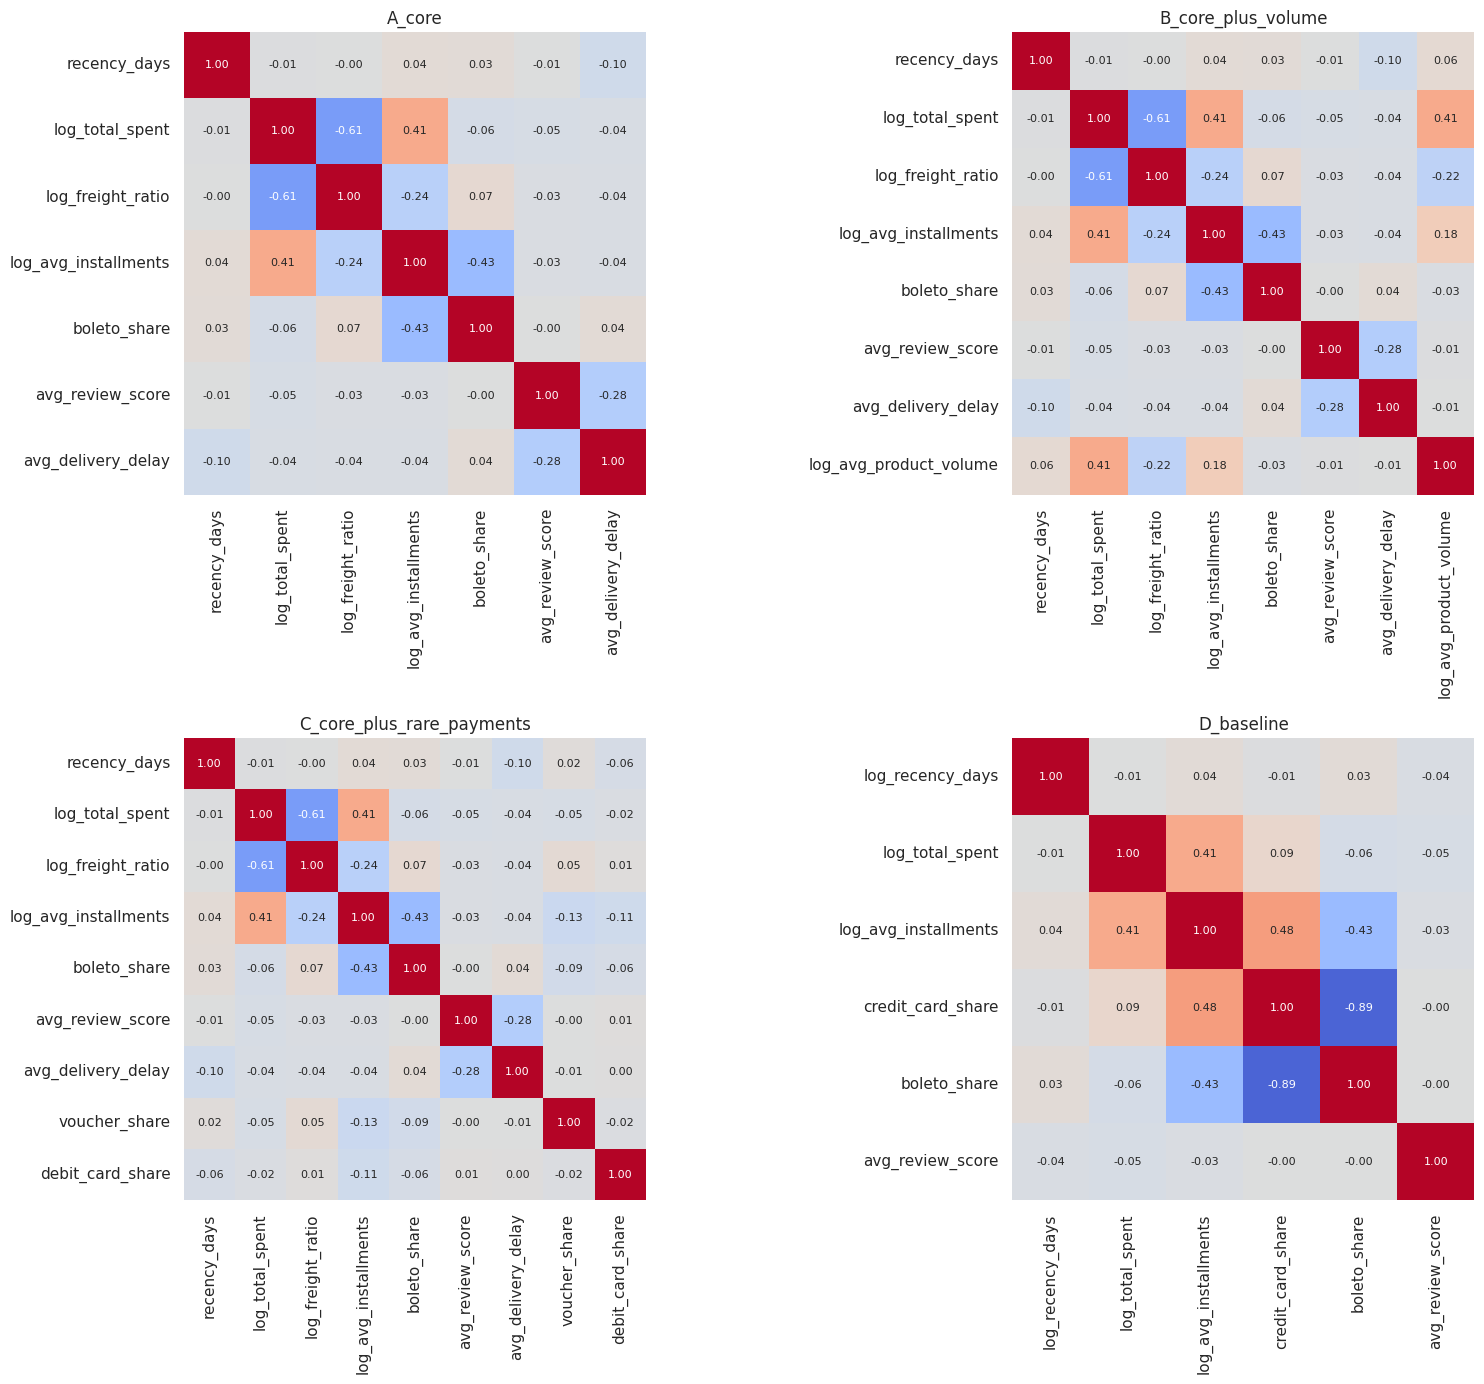

In [191]:
# Plot: one correlation heatmap per feature set (red = positive, blue = negative)
fig, axes = plt.subplots(2, 2, figsize=(17, 14))

for ax, (name, cols) in zip(axes.ravel(), FEATURE_SETS.items()):
    corr = feat[cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [192]:
# List the strongest feature pair in each set and flag pairs above the 0.8 threshold
def top_pairs(data, n=3):
    corr = data.corr()
    upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)   # keep each pair once
    pairs = corr.where(upper).stack()
    return pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(n)

THRESHOLD = 0.8

for name, cols in FEATURE_SETS.items():
    top = top_pairs(feat[cols])
    flag = "WARNING: redundant pair" if top.abs().iloc[0] > THRESHOLD else "ok"
    print(f"\n{name}  ->  {flag}")
    print(top.round(2).to_string())


A_core  ->  ok
log_total_spent       log_freight_ratio      -0.61
log_avg_installments  boleto_share           -0.43
log_total_spent       log_avg_installments    0.41

B_core_plus_volume  ->  ok
log_total_spent       log_freight_ratio      -0.61
log_avg_installments  boleto_share           -0.43
log_total_spent       log_avg_installments    0.41

C_core_plus_rare_payments  ->  ok
log_total_spent       log_freight_ratio      -0.61
log_avg_installments  boleto_share           -0.43
log_total_spent       log_avg_installments    0.41

D_baseline  ->  WARNING: redundant pair
credit_card_share     boleto_share        -0.89
log_avg_installments  credit_card_share    0.48
                      boleto_share        -0.43


## 4.5 - Final checks and saving
We verify that the matrices are clean, then save the transformed features so the next part can start from them without rerunning everything.

In [193]:
# Checks: no missing or infinite values, and all sets contain the same customers
for name, mat in X.items():
    assert mat.notna().all().all(), f"NaN in {name}"
    assert np.isfinite(mat.values).all(), f"Infinite value in {name}"
    assert mat.index.equals(feat.index), f"Index mismatch in {name}"

print("All matrices are clean")
for name, mat in X.items():
    print(f"{name:<28} shape = {mat.shape}")

All matrices are clean
A_core                       shape = (92661, 7)
B_core_plus_volume           shape = (92661, 8)
C_core_plus_rare_payments    shape = (92661, 9)
D_baseline                   shape = (92661, 6)


In [194]:
# `profile` keeps the original, readable values (dollars, days, categories, states).
# We will use it after clustering to describe each segment. It is NOT used for clustering.
if base is not None:
    profile = base.copy()
    assert profile.index.equals(feat.index)
    print(f"Profile table: {profile.shape}")
else:
    profile = None
    print("No profile table: started from the features file (readable values are not available)")


No profile table: started from the features file (readable values are not available)


In [195]:
# Save the transformed (not standardized) features for the next part
if RUN_STEP_4_BUILD:
    feat.to_csv(DATA_DIR / FEAT_FILE)
    print(f"Saved: {FEAT_FILE}  {feat.shape}")
else:
    print("Skipped: the features file was the input, nothing new to save")


Skipped: the features file was the input, nothing new to save


In [196]:
# Download to your PC (works in Google Colab only, skipped elsewhere)
try:
    from google.colab import files
    if RUN_STEP_4_BUILD:
        files.download(FEAT_FILE)
except ImportError:
    print("Not running in Colab: download skipped")


# Part 3 - K-Means on original features vs K-Means on PCA (Step 5)

K-Means runs on every feature set in two variants:

| Variant | Data given to K-Means |
|---|---|
| **original** | the standardized features (`X`) |
| **pca90** | the PCA components that keep 90% of the variance (`X_pca90`) |

| Step | Content |
|---|---|
| 5.0 | Checks, PCA matrices and settings |
| 5.1 | Run K-Means for every set, variant, k and seed, and compute the metrics |
| 5.2 | Results table |
| 5.3 | Plots of the metrics (original vs PCA, per set) |
| 5.4 | Similarity of the clusters from the two variants |
| 5.5 | Side-by-side cluster maps in 2D |
| 5.6 | Summary of the comparison |

**Metrics:** silhouette and ARI (stability across seeds, and agreement between the two variants). Inertia is kept only for the elbow plot and the smallest cluster size as a sanity check.

## 5.0 - Checks, PCA matrices and settings
Checks that `feat` and `X` from Part 2 exist, builds the PCA matrices (2D coordinates for plots and components keeping 90% of the variance), the 10,000-customer plot sample, and fixes the settings used in this part.

In [197]:
# Objects from Part 2 are required
needed = ["feat", "X"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run Part 2 first. Missing objects: {missing}"

# PCA, 2D coordinates (PC1, PC2) of each feature set, used for the cluster maps
pca_full = {name: PCA(random_state=RANDOM_STATE).fit(X[name]) for name in X}
X_pca2 = {name: pd.DataFrame(pca_full[name].transform(X[name])[:, :2],
                             index=X[name].index, columns=["PC1", "PC2"])
          for name in X}

# PCA, components that keep 90% of the variance, used as input to K-Means
X_pca90 = {}
for name in X:
    p = PCA(n_components=0.90, svd_solver="full", random_state=RANDOM_STATE)
    scores = p.fit_transform(X[name])
    X_pca90[name] = pd.DataFrame(scores, index=X[name].index,
                                 columns=[f"PC{i + 1}" for i in range(p.n_components_)])

# Fixed sample of 10,000 customers for the cluster maps
sample_pos = np.random.RandomState(RANDOM_STATE).choice(len(feat), size=min(10000, len(feat)), replace=False)

print({name: X_pca90[name].shape[1] for name in X_pca90}, "components kept at 90% variance")

{'A_core': 6, 'B_core_plus_volume': 7, 'C_core_plus_rare_payments': 7, 'D_baseline': 4} components kept at 90% variance


In [198]:
# Settings
K_RANGE = [3, 4, 5, 6]            # numbers of clusters to test
SEEDS = [42, 7, 21, 99, 123]      # random starts used to measure stability (the first one is the main run)
N_INIT = 10                       # starting points tried by each K-Means fit
SIL_SAMPLE = min(15000, len(feat))               # silhouette is computed on a fixed sample of customers
SETS_TO_RUN = list(X.keys())      # feature sets to evaluate (all by default)

# The two variants that are compared
MATRICES = {"original": X, "pca90": X_pca90}

# One fixed sample of customers for silhouette (the same customers in every evaluation)
sil_pos = np.random.RandomState(RANDOM_STATE).choice(len(feat), size=SIL_SAMPLE, replace=False)
N_COMBOS = len(SETS_TO_RUN) * len(MATRICES)
print(f"Sets: {SETS_TO_RUN}")
print(f"Fits to run: {len(SETS_TO_RUN) * len(MATRICES) * len(K_RANGE) * len(SEEDS)}")

Sets: ['A_core', 'B_core_plus_volume', 'C_core_plus_rare_payments', 'D_baseline']
Fits to run: 160


## 5.1 - Run K-Means and compute the metrics
For every combination of set, variant and k, K-Means is fitted once per seed.

- The run with the first seed (42) is the **main run**: its labels and metrics are reported.
- The other seeds are used only to measure **stability**: if the clusters change a lot between seeds, the solution is fragile.

**Common evaluation space.** The two variants live in different spaces (for example 7 features vs 6 components), so metrics computed in each own space are not comparable. The labels of **both** variants are therefore evaluated in the **original standardized space**. The silhouette in each variant's own space is kept as an extra column.

| Metric | Meaning | Better |
|---|---|---|
| Silhouette | How close a customer is to its own cluster compared with the nearest other cluster (-1 to 1) | higher |
| Inertia | Total squared distance of customers to their cluster center (always falls as k grows) | used for the elbow |
| Stability (ARI) | Agreement between runs with different seeds (1 = identical) | higher |
| Min cluster % | Share of customers in the smallest cluster | not too small |

In [199]:
# Helper: fit K-Means once and return the fitted model
def fit_kmeans(data, k, seed):
    return KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(data)

# Helper: mean ARI over all pairs of runs (how stable the clustering is across seeds)
def mean_pairwise_ari(label_list):
    scores = [adjusted_rand_score(a, b) for a, b in combinations(label_list, 2)]
    return float(np.mean(scores))

In [127]:
# Main loop: K-Means fits and metrics for every set, variant, k and seed
rows = []
labels_main = {}      # (set, variant, k) -> cluster labels of the main run (seed 42)
start = time.time()
combo = 0

for set_name in SETS_TO_RUN:
    X_orig = X[set_name].values                       # the common space for evaluation
    X_orig_sample = X_orig[sil_pos]

    for variant, matrices in MATRICES.items():
        data = matrices[set_name].values              # what K-Means actually clusters

        for k in K_RANGE:
            # Fit once per seed; keep all labels for the stability measure
            runs = [fit_kmeans(data, k, s) for s in SEEDS]
            main = runs[0]                            # seed 42 = main run
            labels = main.labels_
            labels_main[(set_name, variant, k)] = labels

            # Metrics of the main run, measured in the ORIGINAL standardized space
            sil_orig = silhouette_score(X_orig_sample, labels[sil_pos])


            # Silhouette in the variant's own space (for reference only)
            if variant == "original":
                sil_own = sil_orig
            else:
                sil_own = silhouette_score(data[sil_pos], labels[sil_pos])

            sizes = np.bincount(labels, minlength=k) / len(labels) * 100

            rows.append({
                "set": set_name, "variant": variant, "k": k,
                "silhouette": sil_orig,
                "silhouette_own_space": sil_own,
                "inertia": main.inertia_,
                "min_cluster_pct": sizes.min(),
                "stability_ari": mean_pairwise_ari([r.labels_ for r in runs]),
            })
        combo += 1
        print(f"[{combo}/{N_COMBOS}] {set_name:<28} {variant:<9} done  ({time.time() - start:.0f}s elapsed)")

results = pd.DataFrame(rows)
print(f"\nFinished: {len(results)} configurations in {time.time() - start:.0f}s")

[1/8] A_core                       original  done  (26s elapsed)
[2/8] A_core                       pca90     done  (61s elapsed)
[3/8] B_core_plus_volume           original  done  (86s elapsed)
[4/8] B_core_plus_volume           pca90     done  (121s elapsed)
[5/8] C_core_plus_rare_payments    original  done  (144s elapsed)
[6/8] C_core_plus_rare_payments    pca90     done  (179s elapsed)
[7/8] D_baseline                   original  done  (200s elapsed)
[8/8] D_baseline                   pca90     done  (230s elapsed)

Finished: 32 configurations in 230s


## 5.2 - Results table
One row per set, variant and k.

In [ ]:
# Full results table (rounded for reading)
show_cols = ["set", "variant", "k", "silhouette",
             "stability_ari", "min_cluster_pct", "silhouette_own_space"]
results[show_cols].round(3).sort_values(["set", "variant", "k"]).reset_index(drop=True)

## 5.3 - Plots of the metrics
**Elbow plot.** Inertia always decreases as k grows; the elbow is where the decrease becomes slow. Inertia in the PCA space is smaller because there are fewer dimensions, so it is plotted relative to its value at k = 3 to compare the shapes.

**Metric plots.** One column per feature set, one row per metric. The blue line is K-Means on original features, the orange line on PCA components.

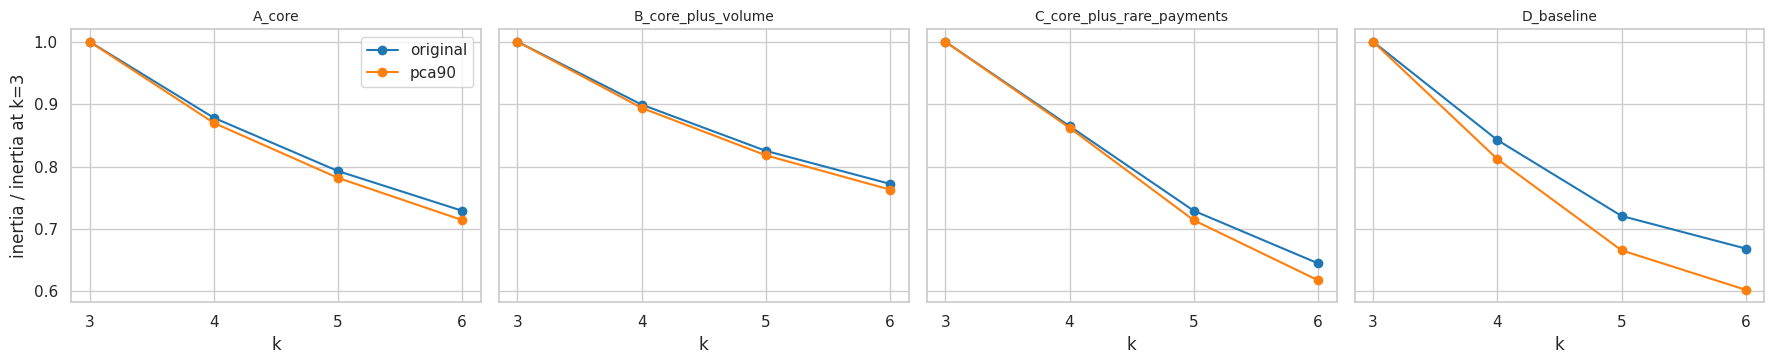

In [129]:
# Plot: elbow curves (inertia relative to k = 3)
fig, axes = plt.subplots(1, len(SETS_TO_RUN), figsize=(4.5 * len(SETS_TO_RUN), 3.8),
                         squeeze=False, sharey=True)

for ax, set_name in zip(axes[0], SETS_TO_RUN):
    for variant, color in [("original", "tab:blue"), ("pca90", "tab:orange")]:
        sub = results[(results["set"] == set_name) & (results["variant"] == variant)].sort_values("k")
        ax.plot(sub["k"], sub["inertia"] / sub["inertia"].iloc[0], marker="o", color=color, label=variant)
    ax.set_title(set_name, fontsize=10)
    ax.set_xlabel("k")
    ax.set_xticks(K_RANGE)
axes[0, 0].set_ylabel("inertia / inertia at k=3")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Plot: two metrics (rows) for each set (columns), original vs PCA
metric_panels = [
    ("silhouette",    "Silhouette (higher = better)"),
    ("stability_ari", "Stability ARI (higher = better)"),
]
n_sets = len(SETS_TO_RUN)
fig, axes = plt.subplots(len(metric_panels), n_sets, figsize=(4.5 * n_sets, 6),
                         squeeze=False, sharex=True)

for j, set_name in enumerate(SETS_TO_RUN):
    for i, (col, title) in enumerate(metric_panels):
        ax = axes[i, j]
        for variant, color in [("original", "tab:blue"), ("pca90", "tab:orange")]:
            sub = results[(results["set"] == set_name) & (results["variant"] == variant)].sort_values("k")
            ax.plot(sub["k"], sub[col], marker="o", color=color, label=variant)
        if i == 0:
            ax.set_title(set_name, fontsize=10)
        if j == 0:
            ax.set_ylabel(title, fontsize=9)
        ax.set_xticks(K_RANGE)
        if i == len(metric_panels) - 1:
            ax.set_xlabel("k")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

## 5.4 - Similarity of the clusters from the two variants
Compares, customer by customer, the labels from K-Means on original features with the labels from K-Means on PCA components, using the **Adjusted Rand Index (ARI)**:

- ARI = 1: both variants group customers identically
- ARI near 0: the groupings are unrelated

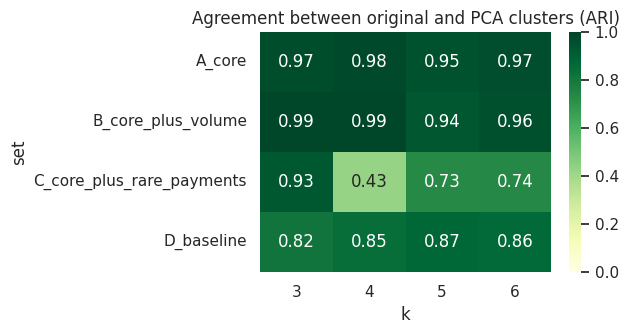

In [131]:
# ARI between the two variants for every set and k
agree_rows = []
for set_name in SETS_TO_RUN:
    for k in K_RANGE:
        ari = adjusted_rand_score(labels_main[(set_name, "original", k)],
                                  labels_main[(set_name, "pca90", k)])
        agree_rows.append({"set": set_name, "k": k, "ari": ari})

agreement = pd.DataFrame(agree_rows).pivot(index="set", columns="k", values="ari")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
sns.heatmap(agreement, annot=True, fmt=".2f", cmap="YlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Agreement between original and PCA clusters (ARI)")
plt.tight_layout()
plt.show()

## 5.5 - Side-by-side cluster maps
Each row is one value of k. Left: clusters found on the original features. Right: clusters found on the PCA components. Both are drawn on the same 2D map (PC1 vs PC2 of the selected feature set, set by `VIS_SET`) with the same 10,000 customers.

**Matching colors.** K-Means numbers its clusters arbitrarily, so the right-hand clusters are relabelled to match the left-hand ones as closely as possible (Hungarian method on the overlap table). The same color then means roughly the same group.

In [132]:
# Helper: rename the clusters of `other` so they match the clusters of `ref` as much as possible
def align_labels(ref, other):
    k = max(ref.max(), other.max()) + 1
    overlap = np.zeros((k, k), dtype=int)
    np.add.at(overlap, (other, ref), 1)                    # rows = other clusters, columns = ref clusters
    row_ind, col_ind = linear_sum_assignment(-overlap)     # best one-to-one matching
    mapping = dict(zip(row_ind, col_ind))
    return np.array([mapping[o] for o in other])

# Helper: cluster sizes as text, e.g. "33% / 25% / 20% / 22%"
def size_text(labels):
    pct = np.bincount(labels) / len(labels) * 100
    return " / ".join(f"{p:.0f}%" for p in pct)

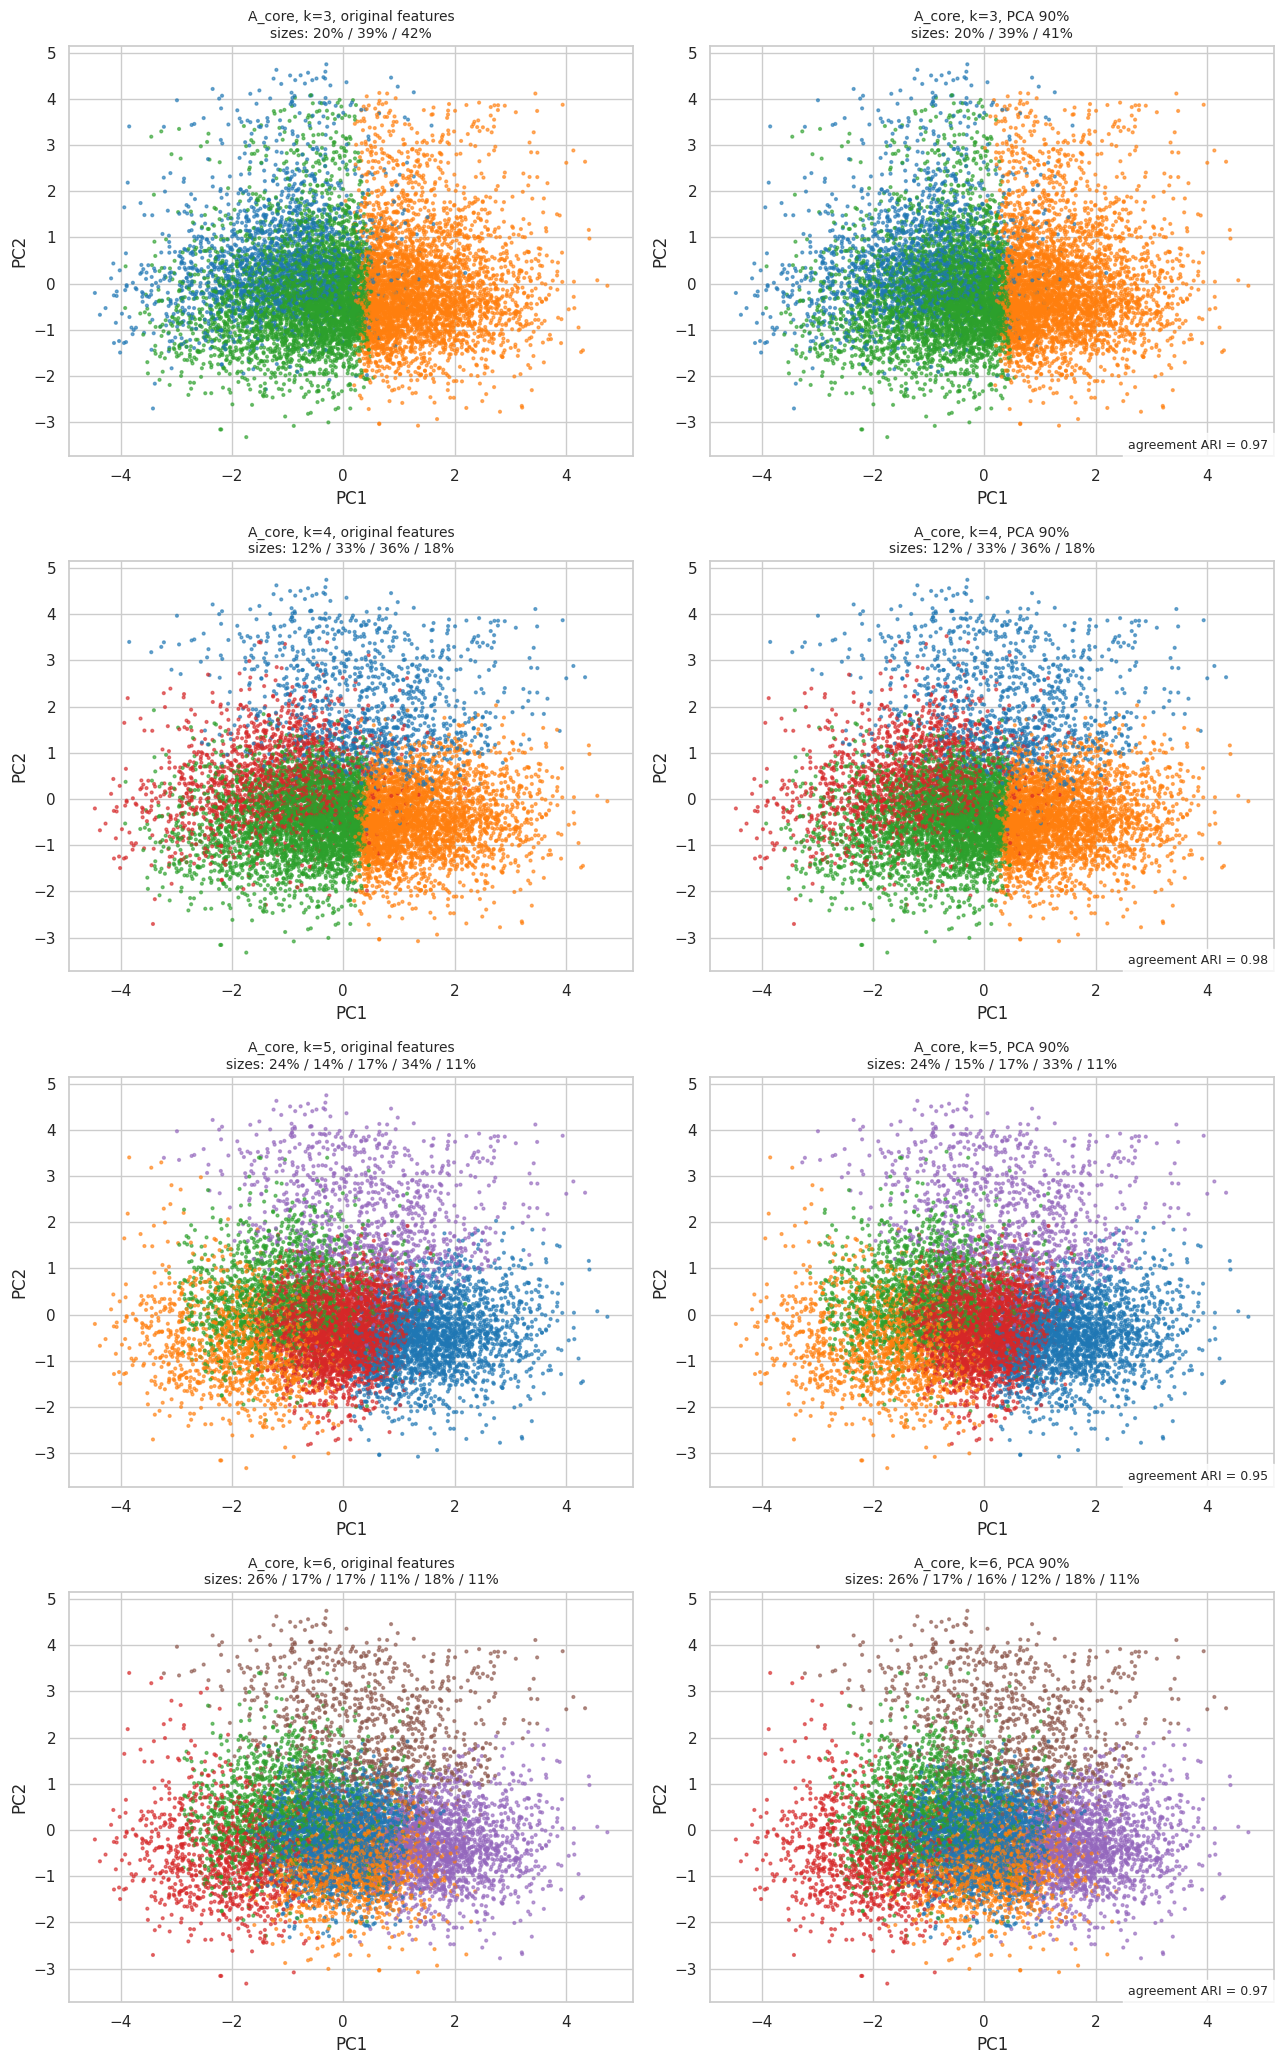

In [133]:
# Plot: original vs PCA clusters, one row per k
VIS_SET = "A_core"                                         # feature set shown on the maps

coords = X_pca2[VIS_SET].iloc[sample_pos]                  # 2D map of the 10,000-customer sample
fig, axes = plt.subplots(len(K_RANGE), 2, figsize=(13, 5.2 * len(K_RANGE)))

for row, k in enumerate(K_RANGE):
    lab_orig = labels_main[(VIS_SET, "original", k)]
    lab_pca = align_labels(lab_orig, labels_main[(VIS_SET, "pca90", k)])
    ari = adjusted_rand_score(lab_orig, lab_pca)

    for col, (name, lab) in enumerate([("original features", lab_orig), ("PCA 90%", lab_pca)]):
        ax = axes[row, col]
        ax.scatter(coords["PC1"], coords["PC2"], c=lab[sample_pos], cmap="tab10",
                   vmin=0, vmax=9, s=4, alpha=0.6)
        ax.set_title(f"{VIS_SET}, k={k}, {name}\nsizes: {size_text(lab)}", fontsize=10)
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
    axes[row, 1].text(0.99, 0.01, f"agreement ARI = {ari:.2f}", transform=axes[row, 1].transAxes,
                      ha="right", va="bottom", fontsize=9, bbox=dict(facecolor="white", alpha=0.8))

plt.tight_layout()
plt.show()

In [134]:
# Plot: interactive 3D cluster map (PC1, PC2, PC3 of the selected feature set)
import plotly.express as px

VIS_SET = "A_core"          # feature set shown
VIS_K = 4                   # number of clusters shown (must be in K_RANGE)

# 3D coordinates of the 10,000-customer sample, and the variance explained by each axis
pcs = pca_full[VIS_SET].transform(X[VIS_SET].iloc[sample_pos])[:, :3]
explained = pca_full[VIS_SET].explained_variance_ratio_[:3] * 100

# Clusters found on the original features, for the same customers
labels_3d = labels_main[(VIS_SET, "original", VIS_K)][sample_pos]

plot_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "PC3": pcs[:, 2],
                        "cluster": labels_3d.astype(str)})

fig = px.scatter_3d(
    plot_df, x="PC1", y="PC2", z="PC3", color="cluster",
    category_orders={"cluster": sorted(plot_df["cluster"].unique())},
    opacity=0.6, title=f"{VIS_SET}, k={VIS_K}, original features (3D PCA map)",
    labels={"PC1": f"PC1 ({explained[0]:.0f}%)",
            "PC2": f"PC2 ({explained[1]:.0f}%)",
            "PC3": f"PC3 ({explained[2]:.0f}%)"},
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=40))
fig.show()

In [135]:
# Plot: interactive 3D cluster map (PC1, PC2, PC3 of the selected feature set)
import plotly.express as px

VIS_SET = "A_core"          # feature set shown
VIS_K = 5                   # number of clusters shown (must be in K_RANGE)

# 3D coordinates of the 10,000-customer sample, and the variance explained by each axis
pcs = pca_full[VIS_SET].transform(X[VIS_SET].iloc[sample_pos])[:, :3]
explained = pca_full[VIS_SET].explained_variance_ratio_[:3] * 100

# Clusters found on the original features, for the same customers
labels_3d = labels_main[(VIS_SET, "original", VIS_K)][sample_pos]

plot_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "PC3": pcs[:, 2],
                        "cluster": labels_3d.astype(str)})

fig = px.scatter_3d(
    plot_df, x="PC1", y="PC2", z="PC3", color="cluster",
    category_orders={"cluster": sorted(plot_df["cluster"].unique())},
    opacity=0.6, title=f"{VIS_SET}, k={VIS_K}, original features (3D PCA map)",
    labels={"PC1": f"PC1 ({explained[0]:.0f}%)",
            "PC2": f"PC2 ({explained[1]:.0f}%)",
            "PC3": f"PC3 ({explained[2]:.0f}%)"},
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=40))
fig.show()

In [136]:
# Plot: interactive 3D cluster map (PC1, PC2, PC3 of the selected feature set)
import plotly.express as px

VIS_SET = "A_core"          # feature set shown
VIS_K = 6                   # number of clusters shown (must be in K_RANGE)

# 3D coordinates of the 10,000-customer sample, and the variance explained by each axis
pcs = pca_full[VIS_SET].transform(X[VIS_SET].iloc[sample_pos])[:, :3]
explained = pca_full[VIS_SET].explained_variance_ratio_[:3] * 100

# Clusters found on the original features, for the same customers
labels_3d = labels_main[(VIS_SET, "original", VIS_K)][sample_pos]

plot_df = pd.DataFrame({"PC1": pcs[:, 0], "PC2": pcs[:, 1], "PC3": pcs[:, 2],
                        "cluster": labels_3d.astype(str)})

fig = px.scatter_3d(
    plot_df, x="PC1", y="PC2", z="PC3", color="cluster",
    category_orders={"cluster": sorted(plot_df["cluster"].unique())},
    opacity=0.6, title=f"{VIS_SET}, k={VIS_K}, original features (3D PCA map)",
    labels={"PC1": f"PC1 ({explained[0]:.0f}%)",
            "PC2": f"PC2 ({explained[1]:.0f}%)",
            "PC3": f"PC3 ({explained[2]:.0f}%)"},
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=40))
fig.show()

## 5.6 - Summary of the comparison
Average difference (PCA minus original) of each metric over all sets and values of k.

In [ ]:
# Summary of the comparison: average difference (PCA minus original) over all sets and k
diff = results.pivot_table(index=["set", "k"], columns="variant",
                           values=["silhouette", "stability_ari"])
summary = pd.DataFrame({
    m: (diff[m]["pca90"] - diff[m]["original"]).mean() for m in ["silhouette", "stability_ari"]
}, index=["average (PCA - original)"]).round(4)
print("Average difference over all sets and k (PCA minus original):")
summary

# Part 4 - DBSCAN and comparison with K-Means (Step 6)

DBSCAN groups customers that sit in **dense areas** of the feature space and labels customers in sparse areas as **noise** (label `-1`). It does not take a number of clusters; it takes two settings:

| Setting | Meaning |
|---|---|
| `eps` | radius of the neighbourhood around a customer (a distance in the standardized space) |
| `min_samples` | number of customers (itself included) needed inside that radius for a customer to be a **core** point |

DBSCAN uses **the same standardized matrix** as K-Means (`X[DB_SET]`), so both models see exactly the same data.

| Step | Content |
|---|---|
| 6.0 | Settings |
| 6.1 | k-distance plot to choose the `eps` range (plays the role of the elbow plot) |
| 6.2 | DBSCAN for every `eps` and `min_samples`, with its metrics |
| 6.3 | Heatmaps of the grid |
| 6.4 | Choice of the final DBSCAN solution |
| 6.5 | Metrics: DBSCAN vs K-Means (silhouette and ARI) |
| 6.6 | Cross-table of K-Means clusters vs DBSCAN clusters |
| 6.7 | Side-by-side 2D cluster maps |
| 6.8 | Side-by-side 3D cluster maps |
| 6.9 | Summary of the comparison |

**Metrics used**

| Metric | How it is computed here | Better |
|---|---|---|
| Silhouette | Same fixed sample of customers as Part 3 (`sil_pos`), in the original standardized space. Noise customers are left out (they belong to no cluster), so the **noise %** is always shown next to it | higher |
| ARI (DBSCAN vs K-Means) | Agreement between the two labelings on the customers DBSCAN did not call noise (1 = same grouping, 0 = unrelated) | context: tells whether the two models find the same groups |
| Cross-table | How the customers of each K-Means cluster are spread over the DBSCAN clusters | read, not scored |

## 6.0 - Settings
`DB_SET` is the feature set clustered by DBSCAN and `KM_K` the K-Means solution it is compared with (A_core with k = 4 was the best K-Means result in Part 3).

`MAX_PAIRS` protects memory: DBSCAN stores every pair of neighbours, and with a large `eps` this can exceed the RAM. An `eps` whose estimated number of pairs is above the limit is skipped and reported.

In [138]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

DB_SET = "A_core"                          # feature set used by DBSCAN (same standardized matrix as K-Means)
KM_K = 4                                   # K-Means solution DBSCAN is compared with (must be in K_RANGE)

MIN_SAMPLES_LIST = [7, 14, 28]             # 1x, 2x (rule of thumb) and 4x the number of features
EPS_FACTORS = [0.6, 0.8, 1.0, 1.2, 1.4]    # eps values tested = knee of the k-distance curve x these factors

MAX_NOISE_PCT = 20                         # the automatic choice ignores solutions with more noise than this
MAX_LARGEST_PCT = 95                       # ... and solutions where one cluster holds almost everyone
MAX_PAIRS = 50_000_000                     # memory guard for the neighbour graph (about 1 GB)

# Force a solution instead of the automatic choice (both must be set, and be in the grid)
DB_EPS = None
DB_MIN_SAMPLES = None

# Display: the largest DBSCAN clusters get their own color, the rest are grouped as "other"
MAX_SHOWN = 8

# Objects from Part 3 are required
needed = ["X", "X_pca2", "pca_full", "labels_main", "sil_pos", "sample_pos", "K_RANGE"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run Part 3 first. Missing objects: {missing}"
assert KM_K in K_RANGE, f"KM_K must be one of {K_RANGE}"

X_db = X[DB_SET].values
km_labels = labels_main[(DB_SET, "original", KM_K)]       # K-Means labels on the same features
n_cust = len(X_db)
print(f"DBSCAN input: {DB_SET}  {X_db.shape}  |  compared with K-Means k={KM_K} on the same features")

DBSCAN input: A_core  (25934, 7)  |  compared with K-Means k=4 on the same features


## 6.1 - k-distance plot (choosing `eps`)
For each customer we measure the distance to its `min_samples`-th nearest neighbour (itself counted as the first) and sort these distances. Most customers have a small distance (they are in dense areas) and a few have a large one (isolated customers). The **knee** of the curve, where it starts to rise steeply, is the usual starting value for `eps`: below it most customers would be noise, above it clusters start to merge.

The knee is found automatically (the point of the normalized curve furthest below the straight line from first to last point), and the grid of `eps` values is built around the knee of the middle `min_samples` value.

Nearest neighbours computed in 3s


,7,14,28
knee eps,1.009,1.145,1.268


eps grid (built around the knee for min_samples=14): [np.float64(0.687), np.float64(0.916), np.float64(1.145), np.float64(1.374), np.float64(1.603)]


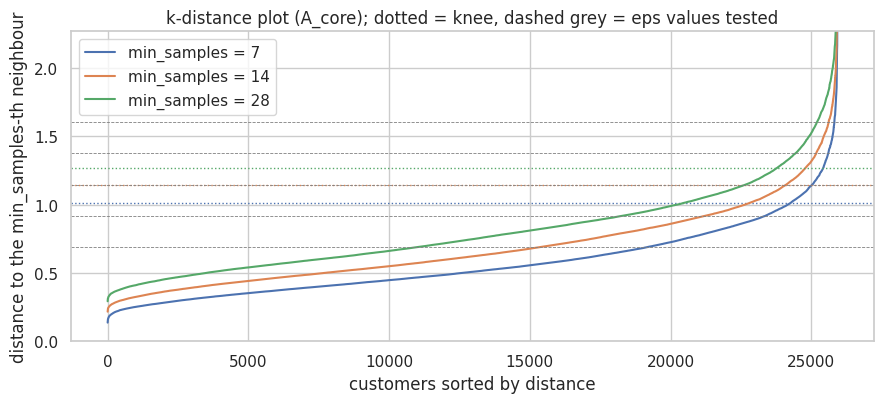

In [139]:
# Nearest neighbours of every customer (fitted once, reused for the grid)
t0 = time.time()
nn = NearestNeighbors().fit(X_db)
k_max = max(MIN_SAMPLES_LIST)
knn_dist, _ = nn.kneighbors(X_db, n_neighbors=k_max)       # column 0 is the customer itself (distance 0)
print(f"Nearest neighbours computed in {time.time() - t0:.0f}s")


def knee_value(sorted_values):
    """Value at the knee of an increasing curve (largest gap below the first-to-last chord)."""
    y = np.asarray(sorted_values, dtype=float)
    x = np.linspace(0, 1, len(y))
    y_norm = (y - y.min()) / (y.max() - y.min())
    return y[np.argmax(x - y_norm)]


knee_eps = {ms: knee_value(np.sort(knn_dist[:, ms - 1])) for ms in MIN_SAMPLES_LIST}
ms_ref = sorted(MIN_SAMPLES_LIST)[len(MIN_SAMPLES_LIST) // 2]          # middle min_samples value
EPS_GRID = sorted({round(knee_eps[ms_ref] * f, 3) for f in EPS_FACTORS})

display(pd.DataFrame({"knee eps": knee_eps}).T.round(3))
print(f"eps grid (built around the knee for min_samples={ms_ref}): {EPS_GRID}")

# Plot: sorted k-distance curves with their knee
fig, ax = plt.subplots(figsize=(9, 4.2))
for ms in MIN_SAMPLES_LIST:
    curve = np.sort(knn_dist[:, ms - 1])
    line, = ax.plot(np.arange(n_cust), curve, label=f"min_samples = {ms}")
    ax.axhline(knee_eps[ms], color=line.get_color(), linestyle=":", linewidth=1)
for eps in EPS_GRID:
    ax.axhline(eps, color="grey", linestyle="--", linewidth=0.6)
ax.set_ylim(0, np.quantile(knn_dist[:, k_max - 1], 0.995) * 1.1)
ax.set_xlabel("customers sorted by distance")
ax.set_ylabel("distance to the min_samples-th neighbour")
ax.set_title(f"k-distance plot ({DB_SET}); dotted = knee, dashed grey = eps values tested")
ax.legend()
plt.tight_layout()
plt.show()

## 6.2 - Run DBSCAN for every `eps` and `min_samples`
The neighbour graph depends only on `eps`, so it is built once per `eps` and reused for every `min_samples` (the labels are identical to running DBSCAN directly, only faster).

For each solution we record: number of clusters, noise %, size of the largest cluster, **silhouette** (non-noise customers of the fixed sample) and **ARI with K-Means** (non-noise customers).

In [140]:
def dbscan_metrics(labels):
    """Descriptive counts plus silhouette and ARI vs K-Means, for one DBSCAN labeling."""
    kept = labels != -1
    cluster_ids = np.unique(labels[kept])
    n_clusters = len(cluster_ids)
    sizes = np.bincount(labels[kept]) if n_clusters else np.array([0])

    row = {
        "n_clusters": n_clusters,
        "noise_pct": 100 * (~kept).mean(),
        "largest_pct": 100 * sizes.max() / n_cust,
        "silhouette": np.nan,
        "ari_vs_kmeans": np.nan,
    }
    if n_clusters >= 2:
        sil_kept = sil_pos[kept[sil_pos]]                      # fixed sample, noise removed
        if len(np.unique(labels[sil_kept])) >= 2:
            row["silhouette"] = silhouette_score(X_db[sil_kept], labels[sil_kept])
    if n_clusters >= 1:
        row["ari_vs_kmeans"] = adjusted_rand_score(km_labels[kept], labels[kept])
    return row


grid_rows = []
db_labels = {}                      # (eps, min_samples) -> DBSCAN labels
probe = np.random.RandomState(RANDOM_STATE).choice(n_cust, size=min(2000, n_cust), replace=False)
t0 = time.time()

for eps in EPS_GRID:
    # Memory guard: estimate the number of neighbour pairs from a small probe of customers
    n_neigh = np.array([len(i) for i in nn.radius_neighbors(X_db[probe], radius=eps, return_distance=False)])
    est_pairs = n_neigh.mean() * n_cust
    if est_pairs > MAX_PAIRS:
        print(f"eps={eps}: skipped, about {est_pairs / 1e6:.0f}M neighbour pairs (limit {MAX_PAIRS / 1e6:.0f}M)")
        continue

    graph = nn.radius_neighbors_graph(X_db, radius=eps, mode="distance")
    for ms in MIN_SAMPLES_LIST:
        labels = DBSCAN(eps=eps, min_samples=ms, metric="precomputed").fit_predict(graph)
        db_labels[(eps, ms)] = labels
        grid_rows.append({"eps": eps, "min_samples": ms, **dbscan_metrics(labels)})
    del graph
    print(f"eps={eps}: done  (~{est_pairs / 1e6:.0f}M pairs, {time.time() - t0:.0f}s elapsed)")

assert grid_rows, "Every eps was skipped: lower EPS_FACTORS or raise MAX_PAIRS"
db_grid = pd.DataFrame(grid_rows)
db_grid.round(3)

eps=0.687: done  (~1M pairs, 10s elapsed)
eps=0.916: done  (~3M pairs, 27s elapsed)
eps=1.145: done  (~8M pairs, 49s elapsed)
eps=1.374: done  (~18M pairs, 71s elapsed)
eps=1.603: done  (~32M pairs, 105s elapsed)


,eps,min_samples,n_clusters,noise_pct,largest_pct,silhouette,ari_vs_kmeans
0,0.687,7,26,16.588,62.281,-0.155,0.437
1,0.687,14,13,25.800,57.627,0.075,0.402
2,0.687,28,5,39.477,48.994,-0.069,0.377
3,0.916,7,3,4.766,76.618,0.238,0.313
4,0.916,14,2,7.662,74.489,0.258,0.317
5,0.916,28,4,12.825,70.390,0.232,0.337
6,1.145,7,2,1.269,79.282,0.246,0.308
7,1.145,14,2,2.260,78.538,0.248,0.310
8,1.145,28,2,3.621,77.636,0.250,0.311
9,1.374,7,1,0.293,99.707,NaN,0.000


## 6.3 - Heatmaps of the grid
Rows are `min_samples`, columns are `eps`. Silhouette and ARI must always be read together with the noise %: a solution can reach a high silhouette simply by calling the hard-to-place customers noise.

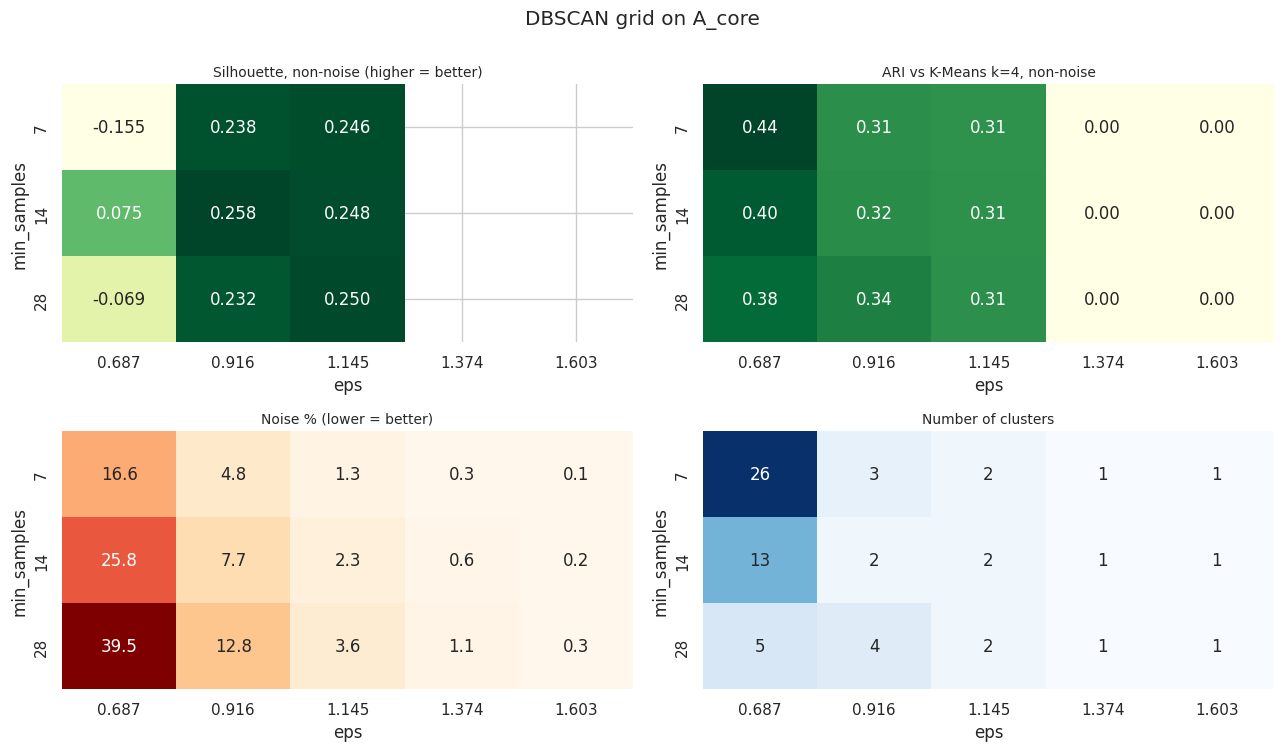

In [141]:
# Plot: four heatmaps over the eps x min_samples grid
panels = [
    ("silhouette",    "Silhouette, non-noise (higher = better)", ".3f", "YlGn"),
    ("ari_vs_kmeans", f"ARI vs K-Means k={KM_K}, non-noise",     ".2f", "YlGn"),
    ("noise_pct",     "Noise % (lower = better)",                ".1f", "OrRd"),
    ("n_clusters",    "Number of clusters",                      ".0f", "Blues"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (col, title, fmt, cmap) in zip(axes.ravel(), panels):
    table = db_grid.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, cbar=False, ax=ax)
    ax.set_title(title, fontsize=10)
plt.suptitle(f"DBSCAN grid on {DB_SET}", y=1.0)
plt.tight_layout()
plt.show()

## 6.4 - Choice of the final DBSCAN solution
Automatic rule: among solutions with **at least 2 clusters**, **noise ≤ `MAX_NOISE_PCT`** and **largest cluster ≤ `MAX_LARGEST_PCT`**, keep the one with the highest silhouette. If no solution passes, the one with the least noise (and at least 2 clusters) is used and a warning is printed. `DB_EPS` and `DB_MIN_SAMPLES` in 6.0 override the rule.

In [142]:
if DB_EPS is not None and DB_MIN_SAMPLES is not None:
    assert (DB_EPS, DB_MIN_SAMPLES) in db_labels, "DB_EPS / DB_MIN_SAMPLES must be a pair from the grid"
    chosen = db_grid[(db_grid["eps"] == DB_EPS) & (db_grid["min_samples"] == DB_MIN_SAMPLES)].iloc[0]
    reason = "set manually"
else:
    ok = db_grid[(db_grid["n_clusters"] >= 2) & (db_grid["noise_pct"] <= MAX_NOISE_PCT)
                 & (db_grid["largest_pct"] <= MAX_LARGEST_PCT) & db_grid["silhouette"].notna()]
    if len(ok):
        chosen = ok.sort_values("silhouette", ascending=False).iloc[0]
        reason = "highest silhouette among solutions that pass the noise and size limits"
    else:
        fallback = db_grid[db_grid["n_clusters"] >= 2]
        assert len(fallback), "No DBSCAN solution with 2 or more clusters: widen the eps grid"
        chosen = fallback.sort_values("noise_pct").iloc[0]
        reason = "WARNING: no solution passes the limits, using the one with the least noise"

best_eps, best_ms = float(chosen["eps"]), int(chosen["min_samples"])
db_final = db_labels[(best_eps, best_ms)]

print(f"Chosen: eps = {best_eps}, min_samples = {best_ms}  ({reason})")
print(f"Clusters: {int(chosen['n_clusters'])} | noise: {chosen['noise_pct']:.1f}% | "
      f"largest cluster: {chosen['largest_pct']:.1f}% | silhouette: {chosen['silhouette']:.3f} | "
      f"ARI vs K-Means: {chosen['ari_vs_kmeans']:.3f}")

# Readable names: DBSCAN clusters ranked by size (D1 = largest); small ones grouped as "D other"
db_sizes = pd.Series(db_final[db_final != -1]).value_counts()
db_rank = {c: f"D{i + 1}" for i, c in enumerate(db_sizes.index[:MAX_SHOWN])}
db_names = np.array([("noise" if l == -1 else db_rank.get(l, "D other")) for l in db_final], dtype=object)
km_names = np.array([f"K{l}" for l in km_labels], dtype=object)

size_table = pd.Series(db_names).value_counts()
display(pd.DataFrame({"customers": size_table, "% of customers": (100 * size_table / n_cust).round(1)}))

Chosen: eps = 0.916, min_samples = 14  (highest silhouette among solutions that pass the noise and size limits)
Clusters: 2 | noise: 7.7% | largest cluster: 74.5% | silhouette: 0.258 | ARI vs K-Means: 0.317


,customers,% of customers
D1,19318,74.5
D2,4629,17.8
noise,1987,7.7


## 6.5 - Metrics: DBSCAN vs K-Means
The silhouette of both models is computed **in the same standardized space and on the same fixed sample** of customers. Because DBSCAN leaves the noise customers out, K-Means is scored twice: on all customers, and on exactly the customers DBSCAN kept (fair one-to-one comparison).

The ARI is also computed against every K-Means k from Part 3, to see which K-Means solution DBSCAN is closest to.

In [143]:
kept = db_final != -1
sil_all = sil_pos                                  # fixed sample used in Part 3
sil_kept = sil_pos[kept[sil_pos]]                  # same sample, DBSCAN noise removed

comparison = pd.DataFrame([
    {"model": f"K-Means k={KM_K}", "customers scored": "all",
     "clusters": KM_K, "customers in a cluster %": 100.0,
     "silhouette": silhouette_score(X_db[sil_all], km_labels[sil_all])},
    {"model": f"K-Means k={KM_K}", "customers scored": "DBSCAN non-noise only",
     "clusters": len(np.unique(km_labels[kept])), "customers in a cluster %": 100.0,
     "silhouette": silhouette_score(X_db[sil_kept], km_labels[sil_kept])},
    {"model": f"DBSCAN eps={best_eps}, min_samples={best_ms}", "customers scored": "non-noise only",
     "clusters": int(chosen["n_clusters"]), "customers in a cluster %": 100 * kept.mean(),
     "silhouette": silhouette_score(X_db[sil_kept], db_final[sil_kept])},
]).set_index("model")
display(comparison.round(3))

# ARI between DBSCAN and each K-Means solution (non-noise customers)
ari_by_k = pd.Series({f"k={k}": adjusted_rand_score(labels_main[(DB_SET, "original", k)][kept], db_final[kept])
                      for k in K_RANGE}, name="ARI with DBSCAN")
display(ari_by_k.to_frame().T.round(3))

,customers scored,clusters,customers in a cluster %,silhouette
model,,,,
K-Means k=4,all,4,100.000,0.211
K-Means k=4,DBSCAN non-noise only,4,100.000,0.226
"DBSCAN eps=0.916, min_samples=14",non-noise only,2,92.338,0.258


,k=3,k=4,k=5,k=6
ARI with DBSCAN,0.411,0.317,0.242,0.177


## 6.6 - Cross-table: K-Means clusters vs DBSCAN clusters
Each row is a K-Means cluster; the columns show where its customers end up in DBSCAN. Left: number of customers. Right: row percentages (each row sums to 100%).

- A row concentrated in one column: DBSCAN finds the same group.
- A row spread over several columns: DBSCAN splits that K-Means cluster.
- A column fed by several rows: DBSCAN merges K-Means clusters.
- A large `noise` column for a row: that K-Means segment lies mostly in sparse areas.

DBSCAN,D1,D2,noise,total
K-Means k=4,,,,
K0,2180,293,746,3219
K1,8224,0,390,8614
K2,8914,0,435,9349
K3,0,4336,416,4752


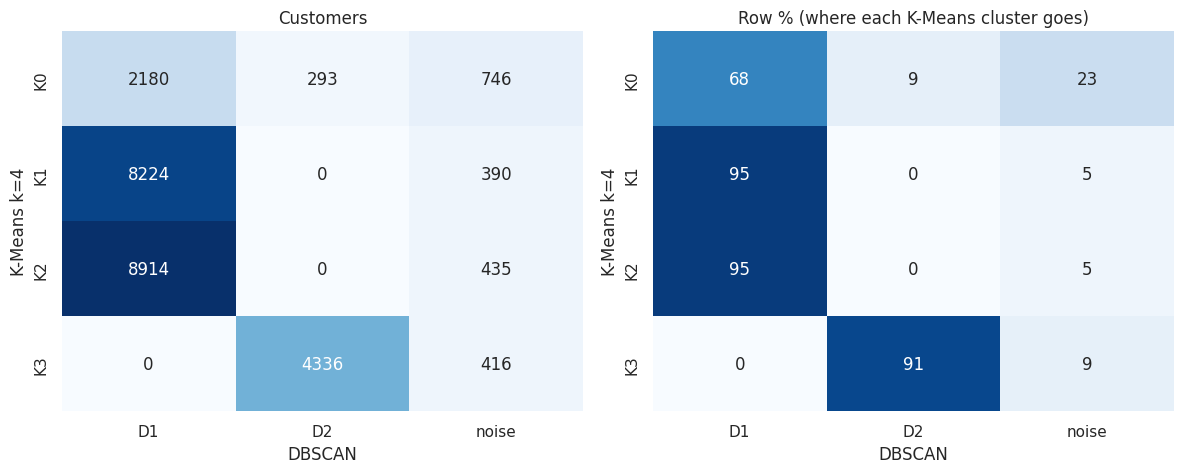

In [144]:
col_order = [f"D{i + 1}" for i in range(len(db_rank))] + \
            [c for c in ["D other", "noise"] if c in set(db_names)]
cross = pd.crosstab(pd.Series(km_names, name=f"K-Means k={KM_K}"),
                    pd.Series(db_names, name="DBSCAN"))[col_order]
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

display(cross.assign(total=cross.sum(axis=1)))

fig, axes = plt.subplots(1, 2, figsize=(max(12, 1.4 * len(col_order) * 2), 0.6 * KM_K + 2.5))
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Customers")
sns.heatmap(cross_pct, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=axes[1])
axes[1].set_title("Row % (where each K-Means cluster goes)")
plt.tight_layout()
plt.show()

## 6.7 - Side-by-side 2D cluster maps
Same 10,000 customers and same 2D map (PC1 vs PC2 of `DB_SET`) as in Part 3. Left: K-Means. Right: DBSCAN, with noise in black and the small clusters grouped as "D other" in light grey.

**Matching colors.** Each DBSCAN cluster is paired with the K-Means cluster it overlaps most (Hungarian method, which also works when the two models have a different number of clusters) and takes its color. DBSCAN clusters with no partner get new colors.

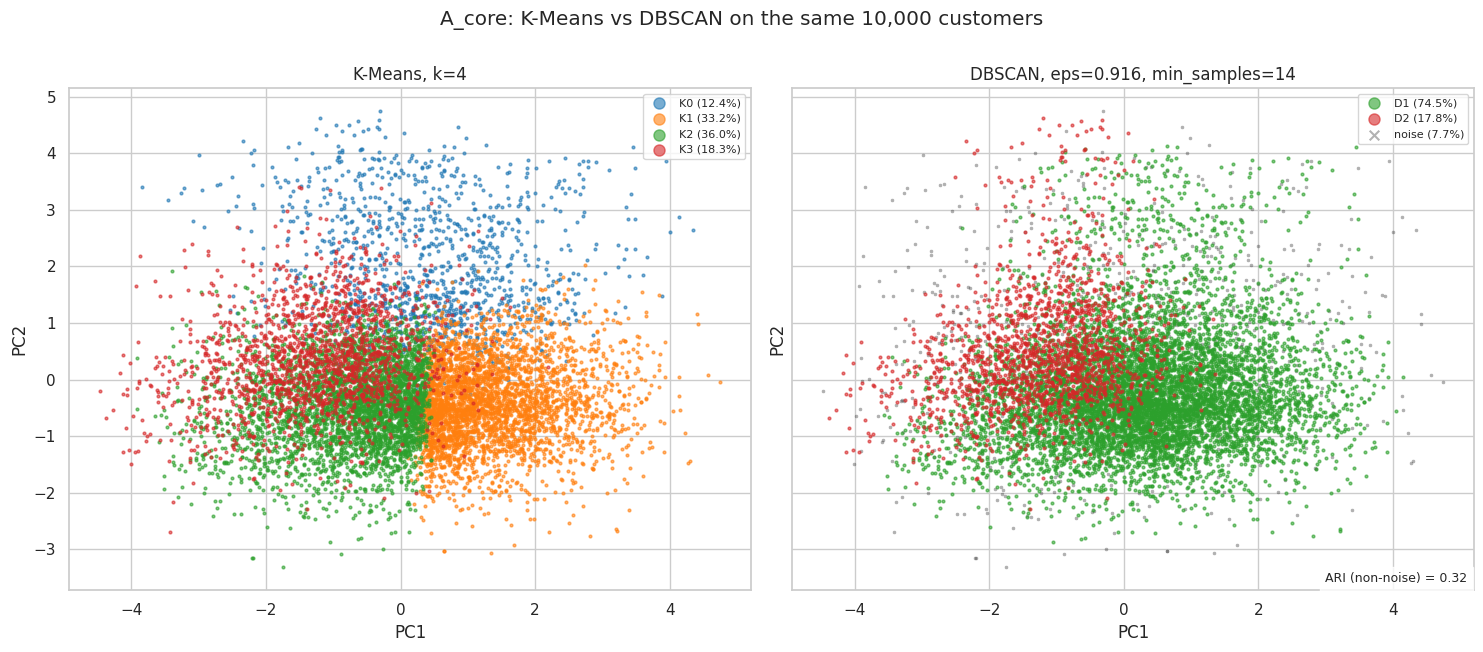

In [145]:
# Colors: K-Means cluster i -> tab10 color i; DBSCAN clusters take the color of their K-Means partner
palette = [plt.cm.tab20(i) for i in range(0, 20, 2)] + [plt.cm.tab20(i) for i in range(1, 20, 2)]
to_hex = lambda c: "#%02x%02x%02x" % tuple(int(255 * v) for v in c[:3])
km_color = {f"K{i}": to_hex(plt.cm.tab10(i)) for i in range(KM_K)}

shown = [f"D{i + 1}" for i in range(len(db_rank))]
overlap = cross.reindex(columns=shown).values                     # rows = K-Means, cols = shown DBSCAN clusters
km_idx, db_idx = linear_sum_assignment(-overlap)
db_color = {shown[d]: km_color[f"K{k}"] for k, d in zip(km_idx, db_idx)}
spare = iter(c for c in map(to_hex, palette) if c not in km_color.values())
for name in shown:
    db_color.setdefault(name, next(spare))
db_color.update({"D other": "#c8c8c8", "noise": "#222222"})
db_color = {name: db_color[name] for name in shown + ["D other", "noise"]}   # legend order D1, D2, ...

coords = X_pca2[DB_SET].iloc[sample_pos]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)

for ax, names, colors, title in [
        (axes[0], km_names, km_color, f"K-Means, k={KM_K}"),
        (axes[1], db_names, db_color, f"DBSCAN, eps={best_eps}, min_samples={best_ms}")]:
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        is_noise = name == "noise"
        pct = 100 * (names == name).mean()
        ax.scatter(coords["PC1"].values[mask], coords["PC2"].values[mask], c=color,
                   s=3 if is_noise else 4, alpha=0.35 if is_noise else 0.6,
                   marker="x" if is_noise else "o", label=f"{name} ({pct:.1f}%)", zorder=1 if is_noise else 2)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(markerscale=4, fontsize=8, loc="best")

axes[1].text(0.99, 0.01, f"ARI (non-noise) = {chosen['ari_vs_kmeans']:.2f}", transform=axes[1].transAxes,
             ha="right", va="bottom", fontsize=9, bbox=dict(facecolor="white", alpha=0.8))
plt.suptitle(f"{DB_SET}: K-Means vs DBSCAN on the same 10,000 customers", y=1.0)
plt.tight_layout()
plt.show()

## 6.8 - Side-by-side 3D cluster maps
Interactive (rotate and zoom). Same customers, same PC1/PC2/PC3 axes and the same colors as the 2D maps. Click a legend entry to hide or show a cluster, for example to hide the noise.

In [146]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pcs3 = pca_full[DB_SET].transform(X[DB_SET].iloc[sample_pos])[:, :3]
explained3 = pca_full[DB_SET].explained_variance_ratio_[:3] * 100
axis_titles = [f"PC{i + 1} ({explained3[i]:.0f}%)" for i in range(3)]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=[f"K-Means, k={KM_K}",
                                    f"DBSCAN, eps={best_eps}, min_samples={best_ms}"])

for col, (names, colors, prefix) in enumerate([(km_names, km_color, "K-Means"),
                                               (db_names, db_color, "DBSCAN")], start=1):
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        fig.add_trace(go.Scatter3d(
            x=pcs3[mask, 0], y=pcs3[mask, 1], z=pcs3[mask, 2], mode="markers",
            marker=dict(size=2, color=color, opacity=0.35 if name == "noise" else 0.6),
            name=f"{prefix}: {name}", legendgroup=prefix), row=1, col=col)

for scene in ["scene", "scene2"]:
    fig.layout[scene].update(xaxis_title=axis_titles[0], yaxis_title=axis_titles[1],
                             zaxis_title=axis_titles[2])
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=60),
                  title=f"{DB_SET}: K-Means vs DBSCAN (3D PCA map, 10,000 customers)",
                  legend=dict(itemsizing="constant"))
fig.show()

## 6.9 - Summary of the comparison
One table with the key numbers of both models, followed by an automatic reading of the results.

In [147]:
sil_km_all = comparison["silhouette"].iloc[0]
sil_km_kept = comparison["silhouette"].iloc[1]
sil_db = comparison["silhouette"].iloc[2]
ari_final = adjusted_rand_score(km_labels[kept], db_final[kept])
best_k_match = ari_by_k.idxmax()

summary_table = pd.DataFrame({
    f"K-Means k={KM_K}": {
        "clusters": KM_K,
        "customers assigned to a cluster %": 100.0,
        "largest cluster %": 100 * np.bincount(km_labels).max() / n_cust,
        "silhouette (all customers)": sil_km_all,
        "silhouette (DBSCAN non-noise customers)": sil_km_kept,
    },
    f"DBSCAN eps={best_eps}, ms={best_ms}": {
        "clusters": int(chosen["n_clusters"]),
        "customers assigned to a cluster %": 100 * kept.mean(),
        "largest cluster %": chosen["largest_pct"],
        "silhouette (all customers)": np.nan,
        "silhouette (DBSCAN non-noise customers)": sil_db,
    },
}).round(3)
display(summary_table)

print("Reading of the results")
print(f"- Silhouette on the same customers: DBSCAN {sil_db:.3f} vs K-Means {sil_km_kept:.3f} "
      f"-> {'DBSCAN' if sil_db > sil_km_kept else 'K-Means'} separates them better.")
print(f"- DBSCAN leaves {100 * (~kept).mean():.1f}% of customers as noise (no segment); "
      f"K-Means assigns everyone.")
print(f"- Largest DBSCAN cluster holds {chosen['largest_pct']:.1f}% of customers "
      f"({'one dominant group: little segmentation' if chosen['largest_pct'] > 70 else 'groups are reasonably balanced'}).")
print(f"- ARI with K-Means k={KM_K}: {ari_final:.2f} "
      f"({'similar groupings' if ari_final >= 0.6 else 'partly similar groupings' if ari_final >= 0.3 else 'different groupings'}); "
      f"closest K-Means solution: {best_k_match} (ARI {ari_by_k.max():.2f}).")

,K-Means k=4,"DBSCAN eps=0.916, ms=14"
clusters,4.000,2.000
customers assigned to a cluster %,100.000,92.338
largest cluster %,36.049,74.489
silhouette (all customers),0.211,NaN
silhouette (DBSCAN non-noise customers),0.226,0.258


Reading of the results
- Silhouette on the same customers: DBSCAN 0.258 vs K-Means 0.226 -> DBSCAN separates them better.
- DBSCAN leaves 7.7% of customers as noise (no segment); K-Means assigns everyone.
- Largest DBSCAN cluster holds 74.5% of customers (one dominant group: little segmentation).
- ARI with K-Means k=4: 0.32 (partly similar groupings); closest K-Means solution: k=3 (ARI 0.41).


In [148]:
# ==================================================================================
# EXPERIMENT SETTINGS - change the values here, then run this cell and the two below
# ==================================================================================
EXP_SET = "A_core"              # feature set used by both models: A_core, B_core_plus_volume,
                                # C_core_plus_rare_payments, D_baseline

# ---- K-Means ----
KM_K_EXP = 2                    # number of clusters
KM_N_INIT_EXP = 10              # starting points tried (the best one is kept)
KM_SEED_EXP = 42                # random seed
KM_SPACE_EXP = "original"       # "original" = standardized features, "pca90" = PCA components (90% variance)

# ---- DBSCAN ----
DB_EPS_EXP = 0.99               # neighbourhood radius (see the k-distance plot in 6.1 for sensible values)
DB_MIN_SAMPLES_EXP = 14         # customers needed within eps to form a dense core (itself included)

# ---- Display / safety ----
EXP_MAX_SHOWN = 8               # largest DBSCAN clusters drawn in color, the rest grouped as "D other"
EXP_MAX_PAIRS = 50_000_000      # memory guard: DBSCAN is refused if eps would create more neighbour pairs
# ==================================================================================

from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors

needed = ["X", "X_pca90", "pca_full", "sample_pos", "sil_pos"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run Parts 2 and 3 first. Missing objects: {missing}"
assert EXP_SET in X, f"EXP_SET must be one of {list(X)}"
assert KM_SPACE_EXP in ("original", "pca90")

exp_X = X[EXP_SET].values                       # common space: both models are evaluated here
exp_n = len(exp_X)

# ---- Fit K-Means ----
km_input = exp_X if KM_SPACE_EXP == "original" else X_pca90[EXP_SET].values
exp_km = KMeans(n_clusters=KM_K_EXP, n_init=KM_N_INIT_EXP, random_state=KM_SEED_EXP).fit_predict(km_input)

# ---- Fit DBSCAN (with a memory check first) ----
exp_nn = NearestNeighbors().fit(exp_X)
probe = np.random.RandomState(0).choice(exp_n, size=min(2000, exp_n), replace=False)
est_pairs = np.mean([len(i) for i in exp_nn.radius_neighbors(exp_X[probe], radius=DB_EPS_EXP,
                                                             return_distance=False)]) * exp_n
assert est_pairs <= EXP_MAX_PAIRS, (
    f"eps={DB_EPS_EXP} would create about {est_pairs / 1e6:.0f}M neighbour pairs "
    f"(limit {EXP_MAX_PAIRS / 1e6:.0f}M): lower DB_EPS_EXP or raise EXP_MAX_PAIRS")
exp_graph = exp_nn.radius_neighbors_graph(exp_X, radius=DB_EPS_EXP, mode="distance")
exp_db = DBSCAN(eps=DB_EPS_EXP, min_samples=DB_MIN_SAMPLES_EXP, metric="precomputed").fit_predict(exp_graph)
del exp_graph

# ---- Metrics: silhouette (same fixed sample, same space) and ARI ----
exp_kept = exp_db != -1
exp_n_db = len(np.unique(exp_db[exp_kept]))
sil_kept_pos = sil_pos[exp_kept[sil_pos]]


def safe_silhouette(pos, labels):
    return silhouette_score(exp_X[pos], labels[pos]) if len(np.unique(labels[pos])) >= 2 else np.nan


exp_metrics = pd.DataFrame({
    f"K-Means k={KM_K_EXP} ({KM_SPACE_EXP})": {
        "clusters": KM_K_EXP,
        "noise %": 0.0,
        "largest cluster %": 100 * np.bincount(exp_km).max() / exp_n,
        "silhouette (all customers)": safe_silhouette(sil_pos, exp_km),
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_km),
    },
    f"DBSCAN eps={DB_EPS_EXP}, ms={DB_MIN_SAMPLES_EXP}": {
        "clusters": exp_n_db,
        "noise %": 100 * (~exp_kept).mean(),
        "largest cluster %": 100 * np.bincount(exp_db[exp_kept]).max() / exp_n if exp_n_db else 0.0,
        "silhouette (all customers)": np.nan,
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_db),
    },
}).round(3)
exp_ari = adjusted_rand_score(exp_km[exp_kept], exp_db[exp_kept]) if exp_n_db else np.nan

display(exp_metrics)
print(f"ARI K-Means vs DBSCAN (non-noise customers): {exp_ari:.3f}")
if exp_n_db < 2:
    print("Note: DBSCAN found fewer than 2 clusters, so its silhouette is undefined. "
          "Try a smaller eps or a smaller min_samples.")

# ---- Readable names and matching colors (used by the 2D and 3D cells) ----
db_size_exp = pd.Series(exp_db[exp_kept]).value_counts()
db_rank_exp = {c: f"D{i + 1}" for i, c in enumerate(db_size_exp.index[:EXP_MAX_SHOWN])}
exp_db_names = np.array([("noise" if l == -1 else db_rank_exp.get(l, "D other")) for l in exp_db], dtype=object)
exp_km_names = np.array([f"K{l}" for l in exp_km], dtype=object)

to_hex = lambda c: "#%02x%02x%02x" % tuple(int(255 * v) for v in c[:3])
km_palette = [to_hex(plt.cm.tab20(i)) for i in range(0, 20, 2)] + [to_hex(plt.cm.tab20(i)) for i in range(1, 20, 2)]
exp_km_color = {f"K{i}": km_palette[i % 20] for i in range(KM_K_EXP)}

# Each DBSCAN cluster takes the color of the K-Means cluster it overlaps most (Hungarian method)
shown_exp = [f"D{i + 1}" for i in range(len(db_rank_exp))]
exp_db_color = {}
if shown_exp:
    overlap = (pd.crosstab(exp_km_names, exp_db_names)
                 .reindex(index=list(exp_km_color), columns=shown_exp, fill_value=0).values)
    km_idx, db_idx = linear_sum_assignment(-overlap)
    exp_db_color = {shown_exp[d]: exp_km_color[f"K{k}"] for k, d in zip(km_idx, db_idx)}
    spare = iter(c for c in km_palette if c not in exp_km_color.values())
    for name in shown_exp:
        exp_db_color.setdefault(name, next(spare, "#8c564b"))
exp_db_color.update({"D other": "#c8c8c8", "noise": "#222222"})
exp_db_color = {name: exp_db_color[name] for name in shown_exp + ["D other", "noise"]}

,K-Means k=2 (original),"DBSCAN eps=0.99, ms=14"
clusters,2.000,2.000
noise %,0.000,5.009
largest cluster %,52.341,76.537
silhouette (all customers),0.174,NaN
silhouette (DBSCAN non-noise customers),0.179,0.253


ARI K-Means vs DBSCAN (non-noise customers): 0.105


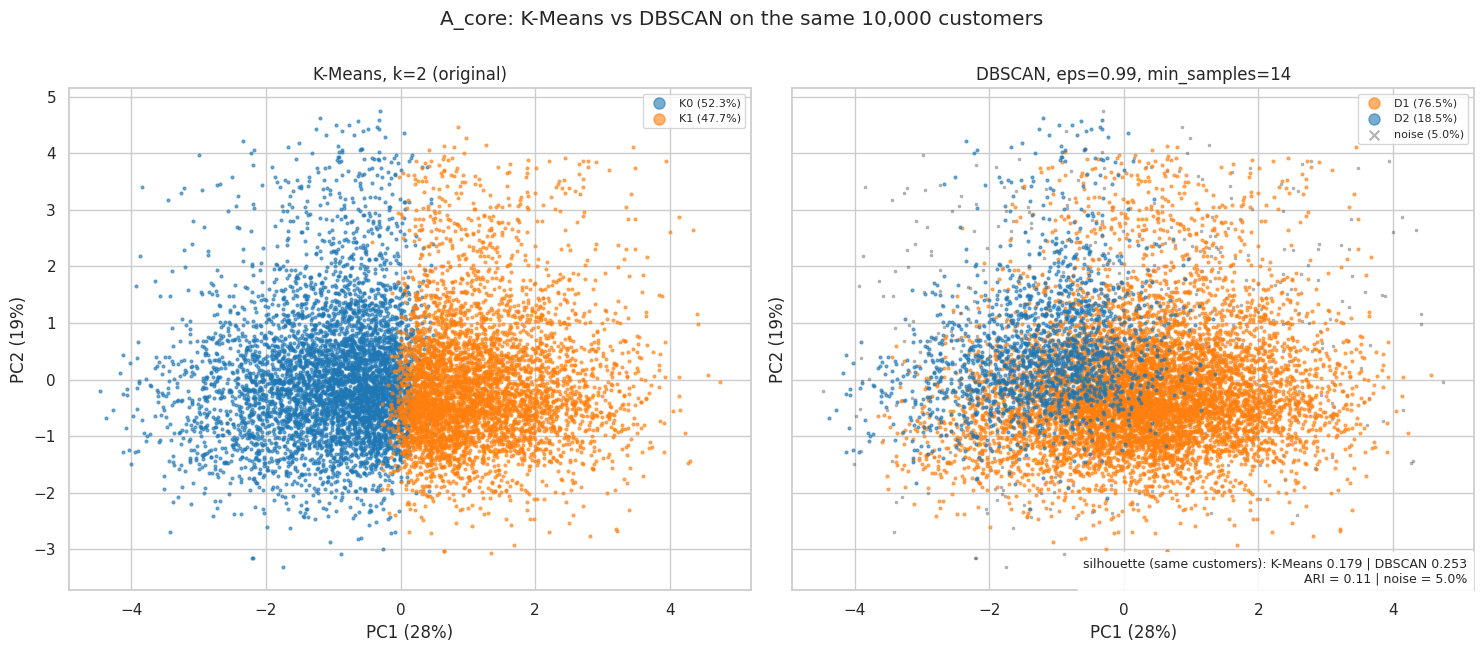

In [149]:
# 2D comparison: K-Means (left) vs DBSCAN (right), same 10,000 customers, PC1 vs PC2 of EXP_SET
coords_exp = pca_full[EXP_SET].transform(X[EXP_SET].iloc[sample_pos])[:, :2]
expl_2d = pca_full[EXP_SET].explained_variance_ratio_[:2] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
panels = [
    (axes[0], exp_km_names, exp_km_color, f"K-Means, k={KM_K_EXP} ({KM_SPACE_EXP})"),
    (axes[1], exp_db_names, exp_db_color, f"DBSCAN, eps={DB_EPS_EXP}, min_samples={DB_MIN_SAMPLES_EXP}"),
]
for ax, names, colors, title in panels:
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        is_noise = name == "noise"
        pct = 100 * (names == name).mean()
        ax.scatter(coords_exp[mask, 0], coords_exp[mask, 1], c=color,
                   s=3 if is_noise else 4, alpha=0.35 if is_noise else 0.6,
                   marker="x" if is_noise else "o", zorder=1 if is_noise else 2,
                   label=f"{name} ({pct:.1f}%)")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({expl_2d[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({expl_2d[1]:.0f}%)")
    ax.legend(markerscale=4, fontsize=8, loc="best")

sil_km_txt, sil_db_txt = exp_metrics.loc["silhouette (DBSCAN non-noise customers)"].values
axes[1].text(0.99, 0.01,
             f"silhouette (same customers): K-Means {sil_km_txt:.3f} | DBSCAN {sil_db_txt:.3f}\n"
             f"ARI = {exp_ari:.2f} | noise = {100 * (~exp_kept).mean():.1f}%",
             transform=axes[1].transAxes, ha="right", va="bottom", fontsize=9,
             bbox=dict(facecolor="white", alpha=0.85))
plt.suptitle(f"{EXP_SET}: K-Means vs DBSCAN on the same 10,000 customers", y=1.0)
plt.tight_layout()
plt.show()

In [150]:
# 3D comparison (interactive): K-Means (left) vs DBSCAN (right), PC1/PC2/PC3 of EXP_SET
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pcs3_exp = pca_full[EXP_SET].transform(X[EXP_SET].iloc[sample_pos])[:, :3]
expl_3d = pca_full[EXP_SET].explained_variance_ratio_[:3] * 100
axis_titles = [f"PC{i + 1} ({expl_3d[i]:.0f}%)" for i in range(3)]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=[f"K-Means, k={KM_K_EXP} ({KM_SPACE_EXP})",
                                    f"DBSCAN, eps={DB_EPS_EXP}, min_samples={DB_MIN_SAMPLES_EXP}"])

for col, (names, colors, prefix) in enumerate([(exp_km_names, exp_km_color, "K-Means"),
                                               (exp_db_names, exp_db_color, "DBSCAN")], start=1):
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        fig.add_trace(go.Scatter3d(
            x=pcs3_exp[mask, 0], y=pcs3_exp[mask, 1], z=pcs3_exp[mask, 2], mode="markers",
            marker=dict(size=2, color=color, opacity=0.35 if name == "noise" else 0.6),
            name=f"{prefix}: {name} ({100 * (names == name).mean():.1f}%)", legendgroup=prefix),
            row=1, col=col)

for scene in ["scene", "scene2"]:
    fig.layout[scene].update(xaxis_title=axis_titles[0], yaxis_title=axis_titles[1],
                             zaxis_title=axis_titles[2])
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=60), legend=dict(itemsizing="constant"),
                  title=f"{EXP_SET}: K-Means vs DBSCAN (3D PCA map, 10,000 customers) | "
                        f"ARI = {exp_ari:.2f}, noise = {100 * (~exp_kept).mean():.1f}%")
fig.show()

In [151]:
# ==================================================================================
# EXPERIMENT SETTINGS - change the values here, then run this cell and the two below
# ==================================================================================
EXP_SET = "A_core"              # feature set used by both models: A_core, B_core_plus_volume,
                                # C_core_plus_rare_payments, D_baseline

# ---- K-Means ----
KM_K_EXP = 3                    # number of clusters
KM_N_INIT_EXP = 10              # starting points tried (the best one is kept)
KM_SEED_EXP = 42                # random seed
KM_SPACE_EXP = "original"       # "original" = standardized features, "pca90" = PCA components (90% variance)

# ---- DBSCAN ----
DB_EPS_EXP = 1.5               # neighbourhood radius (see the k-distance plot in 6.1 for sensible values)
DB_MIN_SAMPLES_EXP = 20         # customers needed within eps to form a dense core (itself included)

# ---- Display / safety ----
EXP_MAX_SHOWN = 8               # largest DBSCAN clusters drawn in color, the rest grouped as "D other"
EXP_MAX_PAIRS = 50_000_000      # memory guard: DBSCAN is refused if eps would create more neighbour pairs
# ==================================================================================

from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors

needed = ["X", "X_pca90", "pca_full", "sample_pos", "sil_pos"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run Parts 2 and 3 first. Missing objects: {missing}"
assert EXP_SET in X, f"EXP_SET must be one of {list(X)}"
assert KM_SPACE_EXP in ("original", "pca90")

exp_X = X[EXP_SET].values                       # common space: both models are evaluated here
exp_n = len(exp_X)

# ---- Fit K-Means ----
km_input = exp_X if KM_SPACE_EXP == "original" else X_pca90[EXP_SET].values
exp_km = KMeans(n_clusters=KM_K_EXP, n_init=KM_N_INIT_EXP, random_state=KM_SEED_EXP).fit_predict(km_input)

# ---- Fit DBSCAN (with a memory check first) ----
exp_nn = NearestNeighbors().fit(exp_X)
probe = np.random.RandomState(0).choice(exp_n, size=min(2000, exp_n), replace=False)
est_pairs = np.mean([len(i) for i in exp_nn.radius_neighbors(exp_X[probe], radius=DB_EPS_EXP,
                                                             return_distance=False)]) * exp_n
assert est_pairs <= EXP_MAX_PAIRS, (
    f"eps={DB_EPS_EXP} would create about {est_pairs / 1e6:.0f}M neighbour pairs "
    f"(limit {EXP_MAX_PAIRS / 1e6:.0f}M): lower DB_EPS_EXP or raise EXP_MAX_PAIRS")
exp_graph = exp_nn.radius_neighbors_graph(exp_X, radius=DB_EPS_EXP, mode="distance")
exp_db = DBSCAN(eps=DB_EPS_EXP, min_samples=DB_MIN_SAMPLES_EXP, metric="precomputed").fit_predict(exp_graph)
del exp_graph

# ---- Metrics: silhouette (same fixed sample, same space) and ARI ----
exp_kept = exp_db != -1
exp_n_db = len(np.unique(exp_db[exp_kept]))
sil_kept_pos = sil_pos[exp_kept[sil_pos]]


def safe_silhouette(pos, labels):
    return silhouette_score(exp_X[pos], labels[pos]) if len(np.unique(labels[pos])) >= 2 else np.nan


exp_metrics = pd.DataFrame({
    f"K-Means k={KM_K_EXP} ({KM_SPACE_EXP})": {
        "clusters": KM_K_EXP,
        "noise %": 0.0,
        "largest cluster %": 100 * np.bincount(exp_km).max() / exp_n,
        "silhouette (all customers)": safe_silhouette(sil_pos, exp_km),
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_km),
    },
    f"DBSCAN eps={DB_EPS_EXP}, ms={DB_MIN_SAMPLES_EXP}": {
        "clusters": exp_n_db,
        "noise %": 100 * (~exp_kept).mean(),
        "largest cluster %": 100 * np.bincount(exp_db[exp_kept]).max() / exp_n if exp_n_db else 0.0,
        "silhouette (all customers)": np.nan,
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_db),
    },
}).round(3)
exp_ari = adjusted_rand_score(exp_km[exp_kept], exp_db[exp_kept]) if exp_n_db else np.nan

display(exp_metrics)
print(f"ARI K-Means vs DBSCAN (non-noise customers): {exp_ari:.3f}")
if exp_n_db < 2:
    print("Note: DBSCAN found fewer than 2 clusters, so its silhouette is undefined. "
          "Try a smaller eps or a smaller min_samples.")

# ---- Readable names and matching colors (used by the 2D and 3D cells) ----
db_size_exp = pd.Series(exp_db[exp_kept]).value_counts()
db_rank_exp = {c: f"D{i + 1}" for i, c in enumerate(db_size_exp.index[:EXP_MAX_SHOWN])}
exp_db_names = np.array([("noise" if l == -1 else db_rank_exp.get(l, "D other")) for l in exp_db], dtype=object)
exp_km_names = np.array([f"K{l}" for l in exp_km], dtype=object)

to_hex = lambda c: "#%02x%02x%02x" % tuple(int(255 * v) for v in c[:3])
km_palette = [to_hex(plt.cm.tab20(i)) for i in range(0, 20, 2)] + [to_hex(plt.cm.tab20(i)) for i in range(1, 20, 2)]
exp_km_color = {f"K{i}": km_palette[i % 20] for i in range(KM_K_EXP)}

# Each DBSCAN cluster takes the color of the K-Means cluster it overlaps most (Hungarian method)
shown_exp = [f"D{i + 1}" for i in range(len(db_rank_exp))]
exp_db_color = {}
if shown_exp:
    overlap = (pd.crosstab(exp_km_names, exp_db_names)
                 .reindex(index=list(exp_km_color), columns=shown_exp, fill_value=0).values)
    km_idx, db_idx = linear_sum_assignment(-overlap)
    exp_db_color = {shown_exp[d]: exp_km_color[f"K{k}"] for k, d in zip(km_idx, db_idx)}
    spare = iter(c for c in km_palette if c not in exp_km_color.values())
    for name in shown_exp:
        exp_db_color.setdefault(name, next(spare, "#8c564b"))
exp_db_color.update({"D other": "#c8c8c8", "noise": "#222222"})
exp_db_color = {name: exp_db_color[name] for name in shown_exp + ["D other", "noise"]}

,K-Means k=3 (original),"DBSCAN eps=1.5, ms=20"
clusters,3.000,1.000
noise %,0.000,0.328
largest cluster %,41.563,99.672
silhouette (all customers),0.201,NaN
silhouette (DBSCAN non-noise customers),0.202,NaN


ARI K-Means vs DBSCAN (non-noise customers): 0.000
Note: DBSCAN found fewer than 2 clusters, so its silhouette is undefined. Try a smaller eps or a smaller min_samples.


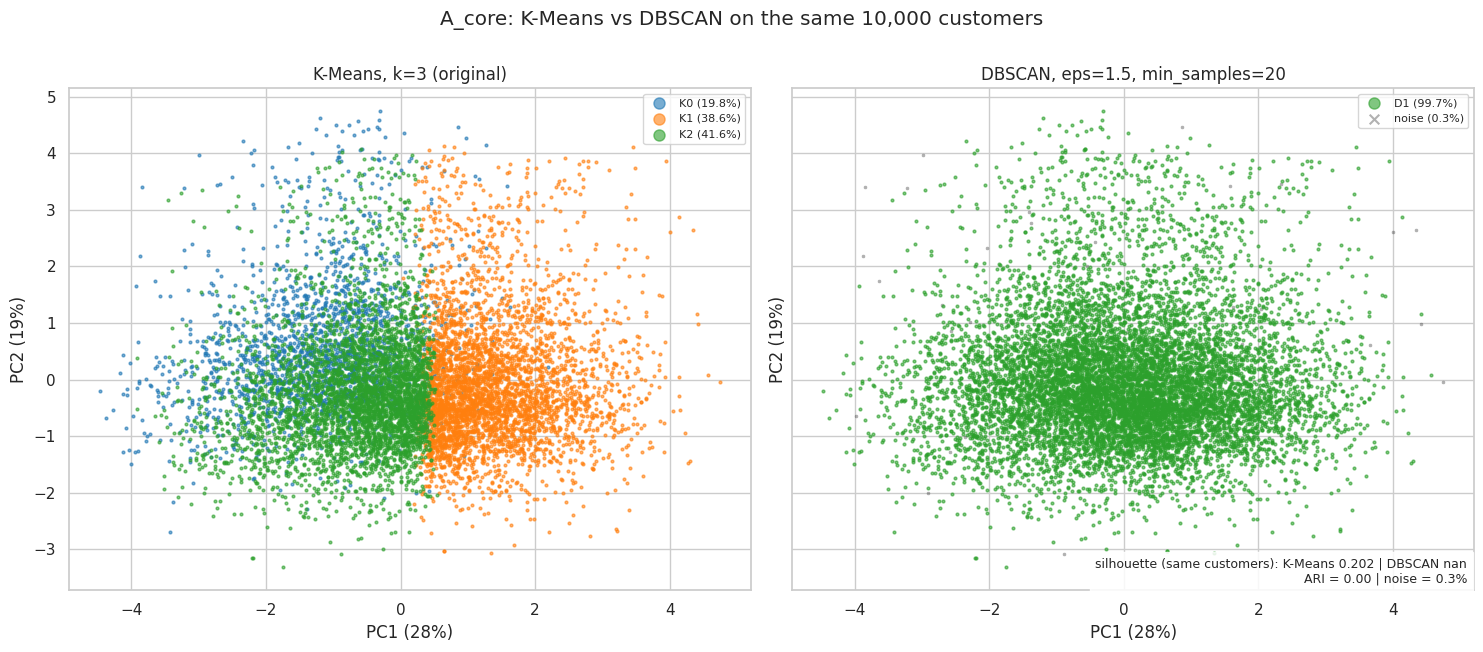

In [152]:
# 2D comparison: K-Means (left) vs DBSCAN (right), same 10,000 customers, PC1 vs PC2 of EXP_SET
coords_exp = pca_full[EXP_SET].transform(X[EXP_SET].iloc[sample_pos])[:, :2]
expl_2d = pca_full[EXP_SET].explained_variance_ratio_[:2] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
panels = [
    (axes[0], exp_km_names, exp_km_color, f"K-Means, k={KM_K_EXP} ({KM_SPACE_EXP})"),
    (axes[1], exp_db_names, exp_db_color, f"DBSCAN, eps={DB_EPS_EXP}, min_samples={DB_MIN_SAMPLES_EXP}"),
]
for ax, names, colors, title in panels:
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        is_noise = name == "noise"
        pct = 100 * (names == name).mean()
        ax.scatter(coords_exp[mask, 0], coords_exp[mask, 1], c=color,
                   s=3 if is_noise else 4, alpha=0.35 if is_noise else 0.6,
                   marker="x" if is_noise else "o", zorder=1 if is_noise else 2,
                   label=f"{name} ({pct:.1f}%)")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({expl_2d[0]:.0f}%)")
    ax.set_ylabel(f"PC2 ({expl_2d[1]:.0f}%)")
    ax.legend(markerscale=4, fontsize=8, loc="best")

sil_km_txt, sil_db_txt = exp_metrics.loc["silhouette (DBSCAN non-noise customers)"].values
axes[1].text(0.99, 0.01,
             f"silhouette (same customers): K-Means {sil_km_txt:.3f} | DBSCAN {sil_db_txt:.3f}\n"
             f"ARI = {exp_ari:.2f} | noise = {100 * (~exp_kept).mean():.1f}%",
             transform=axes[1].transAxes, ha="right", va="bottom", fontsize=9,
             bbox=dict(facecolor="white", alpha=0.85))
plt.suptitle(f"{EXP_SET}: K-Means vs DBSCAN on the same 10,000 customers", y=1.0)
plt.tight_layout()
plt.show()

In [153]:
# ==================================================================================
# EXPERIMENT SETTINGS - change the values here, then run this cell and the two below
# ==================================================================================
EXP_SET = "A_core"              # feature set used by both models: A_core, B_core_plus_volume,
                                # C_core_plus_rare_payments, D_baseline

# ---- K-Means ----
KM_K_EXP = 3                    # number of clusters
KM_N_INIT_EXP = 10              # starting points tried (the best one is kept)
KM_SEED_EXP = 42                # random seed
KM_SPACE_EXP = "original"       # "original" = standardized features, "pca90" = PCA components (90% variance)

# ---- DBSCAN ----
DB_EPS_EXP = 0.99               # neighbourhood radius (see the k-distance plot in 6.1 for sensible values)
DB_MIN_SAMPLES_EXP = 15         # customers needed within eps to form a dense core (itself included)

# ---- Display / safety ----
EXP_MAX_SHOWN = 8               # largest DBSCAN clusters drawn in color, the rest grouped as "D other"
EXP_MAX_PAIRS = 50_000_000      # memory guard: DBSCAN is refused if eps would create more neighbour pairs
# ==================================================================================

from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors

needed = ["X", "X_pca90", "pca_full", "sample_pos", "sil_pos"]
missing = [v for v in needed if v not in globals()]
assert not missing, f"Run Parts 2 and 3 first. Missing objects: {missing}"
assert EXP_SET in X, f"EXP_SET must be one of {list(X)}"
assert KM_SPACE_EXP in ("original", "pca90")

exp_X = X[EXP_SET].values                       # common space: both models are evaluated here
exp_n = len(exp_X)

# ---- Fit K-Means ----
km_input = exp_X if KM_SPACE_EXP == "original" else X_pca90[EXP_SET].values
exp_km = KMeans(n_clusters=KM_K_EXP, n_init=KM_N_INIT_EXP, random_state=KM_SEED_EXP).fit_predict(km_input)

# ---- Fit DBSCAN (with a memory check first) ----
exp_nn = NearestNeighbors().fit(exp_X)
probe = np.random.RandomState(0).choice(exp_n, size=min(2000, exp_n), replace=False)
est_pairs = np.mean([len(i) for i in exp_nn.radius_neighbors(exp_X[probe], radius=DB_EPS_EXP,
                                                             return_distance=False)]) * exp_n
assert est_pairs <= EXP_MAX_PAIRS, (
    f"eps={DB_EPS_EXP} would create about {est_pairs / 1e6:.0f}M neighbour pairs "
    f"(limit {EXP_MAX_PAIRS / 1e6:.0f}M): lower DB_EPS_EXP or raise EXP_MAX_PAIRS")
exp_graph = exp_nn.radius_neighbors_graph(exp_X, radius=DB_EPS_EXP, mode="distance")
exp_db = DBSCAN(eps=DB_EPS_EXP, min_samples=DB_MIN_SAMPLES_EXP, metric="precomputed").fit_predict(exp_graph)
del exp_graph

# ---- Metrics: silhouette (same fixed sample, same space) and ARI ----
exp_kept = exp_db != -1
exp_n_db = len(np.unique(exp_db[exp_kept]))
sil_kept_pos = sil_pos[exp_kept[sil_pos]]


def safe_silhouette(pos, labels):
    return silhouette_score(exp_X[pos], labels[pos]) if len(np.unique(labels[pos])) >= 2 else np.nan


exp_metrics = pd.DataFrame({
    f"K-Means k={KM_K_EXP} ({KM_SPACE_EXP})": {
        "clusters": KM_K_EXP,
        "noise %": 0.0,
        "largest cluster %": 100 * np.bincount(exp_km).max() / exp_n,
        "silhouette (all customers)": safe_silhouette(sil_pos, exp_km),
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_km),
    },
    f"DBSCAN eps={DB_EPS_EXP}, ms={DB_MIN_SAMPLES_EXP}": {
        "clusters": exp_n_db,
        "noise %": 100 * (~exp_kept).mean(),
        "largest cluster %": 100 * np.bincount(exp_db[exp_kept]).max() / exp_n if exp_n_db else 0.0,
        "silhouette (all customers)": np.nan,
        "silhouette (DBSCAN non-noise customers)": safe_silhouette(sil_kept_pos, exp_db),
    },
}).round(3)
exp_ari = adjusted_rand_score(exp_km[exp_kept], exp_db[exp_kept]) if exp_n_db else np.nan

display(exp_metrics)
print(f"ARI K-Means vs DBSCAN (non-noise customers): {exp_ari:.3f}")
if exp_n_db < 2:
    print("Note: DBSCAN found fewer than 2 clusters, so its silhouette is undefined. "
          "Try a smaller eps or a smaller min_samples.")

# ---- Readable names and matching colors (used by the 2D and 3D cells) ----
db_size_exp = pd.Series(exp_db[exp_kept]).value_counts()
db_rank_exp = {c: f"D{i + 1}" for i, c in enumerate(db_size_exp.index[:EXP_MAX_SHOWN])}
exp_db_names = np.array([("noise" if l == -1 else db_rank_exp.get(l, "D other")) for l in exp_db], dtype=object)
exp_km_names = np.array([f"K{l}" for l in exp_km], dtype=object)

to_hex = lambda c: "#%02x%02x%02x" % tuple(int(255 * v) for v in c[:3])
km_palette = [to_hex(plt.cm.tab20(i)) for i in range(0, 20, 2)] + [to_hex(plt.cm.tab20(i)) for i in range(1, 20, 2)]
exp_km_color = {f"K{i}": km_palette[i % 20] for i in range(KM_K_EXP)}

# Each DBSCAN cluster takes the color of the K-Means cluster it overlaps most (Hungarian method)
shown_exp = [f"D{i + 1}" for i in range(len(db_rank_exp))]
exp_db_color = {}
if shown_exp:
    overlap = (pd.crosstab(exp_km_names, exp_db_names)
                 .reindex(index=list(exp_km_color), columns=shown_exp, fill_value=0).values)
    km_idx, db_idx = linear_sum_assignment(-overlap)
    exp_db_color = {shown_exp[d]: exp_km_color[f"K{k}"] for k, d in zip(km_idx, db_idx)}
    spare = iter(c for c in km_palette if c not in exp_km_color.values())
    for name in shown_exp:
        exp_db_color.setdefault(name, next(spare, "#8c564b"))
exp_db_color.update({"D other": "#c8c8c8", "noise": "#222222"})
exp_db_color = {name: exp_db_color[name] for name in shown_exp + ["D other", "noise"]}

,K-Means k=3 (original),"DBSCAN eps=0.99, ms=15"
clusters,3.000,2.000
noise %,0.000,5.248
largest cluster %,41.563,76.382
silhouette (all customers),0.201,NaN
silhouette (DBSCAN non-noise customers),0.210,0.253


ARI K-Means vs DBSCAN (non-noise customers): 0.411


In [154]:
# 3D comparison (interactive): K-Means (left) vs DBSCAN (right), PC1/PC2/PC3 of EXP_SET
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pcs3_exp = pca_full[EXP_SET].transform(X[EXP_SET].iloc[sample_pos])[:, :3]
expl_3d = pca_full[EXP_SET].explained_variance_ratio_[:3] * 100
axis_titles = [f"PC{i + 1} ({expl_3d[i]:.0f}%)" for i in range(3)]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=[f"K-Means, k={KM_K_EXP} ({KM_SPACE_EXP})",
                                    f"DBSCAN, eps={DB_EPS_EXP}, min_samples={DB_MIN_SAMPLES_EXP}"])

for col, (names, colors, prefix) in enumerate([(exp_km_names, exp_km_color, "K-Means"),
                                               (exp_db_names, exp_db_color, "DBSCAN")], start=1):
    sample_names = names[sample_pos]
    for name, color in colors.items():
        mask = sample_names == name
        if not mask.any():
            continue
        fig.add_trace(go.Scatter3d(
            x=pcs3_exp[mask, 0], y=pcs3_exp[mask, 1], z=pcs3_exp[mask, 2], mode="markers",
            marker=dict(size=2, color=color, opacity=0.35 if name == "noise" else 0.6),
            name=f"{prefix}: {name} ({100 * (names == name).mean():.1f}%)", legendgroup=prefix),
            row=1, col=col)

for scene in ["scene", "scene2"]:
    fig.layout[scene].update(xaxis_title=axis_titles[0], yaxis_title=axis_titles[1],
                             zaxis_title=axis_titles[2])
fig.update_layout(height=700, margin=dict(l=0, r=0, b=0, t=60), legend=dict(itemsizing="constant"),
                  title=f"{EXP_SET}: K-Means vs DBSCAN (3D PCA map, 10,000 customers) | "
                        f"ARI = {exp_ari:.2f}, noise = {100 * (~exp_kept).mean():.1f}%")
fig.show()